# E117 · Would that headline finding replicate? The publication filter, 76 repeated psychology experiments and a forecast that has to earn trust

| | |
|---|---|
| **Type** | Advanced worked example - read, run, modify |
| **Data** | Real: the master data file of the **Reproducibility Project: Psychology** (Open Science Collaboration 2015, *Science* 349:aac4716), `rpp_data.csv` from OSF project ezcuj, **CC0 1.0** (public domain dedication, checked through the OSF API on 2026-11-06). Built by `tools/build_e117_rpp.py`: the 97 studies with an effect size and a sample size for both the original and the repeat, of which 76 one-degree-of-freedom tests of a claimed effect are modelled |
| **You will learn** | Why a published p-value is a **selected** observation, in a toy world · a **null/real mixture** with the true effect integrated out · a **publication-selection likelihood** (Hedges 1992) in **closed form**, checked against quadrature · why selection changes the *population* the model learns · an **exact 10-fold track record** against simple base rates, with a PSIS cross-check and a calibration slope · simulation recovery, including a world where most findings are not real, and sensitivity · a news reader's table of P(real) against P(replicates) · for the public: a **track-record plot**, icon shelves with partial fills, a risk ladder, calibrated-language strips and a **publication-filter GIF** |

In [1]:
import os

for v_ in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[v_] = "1"  # nutpie runs chains as threads: one BLAS pool per chain would fight

import logging
import sys
import textwrap
import time
import warnings

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import nutpie
import pandas as pd
import pymc as pm
import pytensor
import pytensor.tensor as pt
import xarray as xr
from IPython.display import Markdown, display
from matplotlib.patches import Circle, FancyBboxPatch, Rectangle
from scipy import integrate, special, stats

from pymc_challenges import data
from pymc_challenges import public as pub

RANDOM_SEED = 117
rng = np.random.default_rng(RANDOM_SEED)
az.style.use("arviz-variat")
logging.getLogger("pymc").setLevel(logging.WARNING)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="arviz")
warnings.filterwarnings("ignore", message="There are no gridspecs with layoutgrids")
sys.modules.pop("jax", None)  # arviz leaves a lazy jax stub that makes matplotlib import all of JAX
pd.set_option("display.width", 160)
T_START = time.time()
TIMES = {}
INK, MUTED, LIGHT, HI, LO = pub.INK, pub.MUTED, pub.LIGHT, pub.HI, pub.LO


def wrap(text, width=90):
    return "\n".join(textwrap.fill(t, width) for t in text.split("\n"))


print(f"PyMC {pm.__version__}, ArviZ {az.__version__}, nutpie {nutpie.__version__}")

PyMC 6.3.2, ArviZ 1.3.0, nutpie 0.16.11


## In plain words

**The question.** Is a newly published psychology finding real, and would it show up again?

**What we did.** In 2015, 270 researchers repeated 100 published psychology experiments; a
repeat *succeeded* if it was significant again (p below .05), in the same direction. Journals
mostly print results that pass that test, a publication filter; the repeats were published
whatever they found. We modelled 76 original-and-repeat pairs, treating each finding as real or
as no effect at all, with the filter written into the model.

**What we found.** About 65 in 100 published findings like these are real (9 in 10 in
cognitive, 4 in 10 in social psychology) but smaller than reported: a p = .049 finding with 100
people repeats about 32 times in 100 (cognitive) or 6 (social). On repeats it had not seen, the
model expected 28 successes and 26 happened, but guessing each field's past success rate (about
1 in 2 for cognitive, 1 in 4 for social psychology) did almost as well.

**How sure are we.** Of published findings like these, it is *virtually certain* (99.3%) that most are real effects: *virtually certain* (>99.9%) for cognitive psychology, but *unlikely* (16%) for social psychology. We have *medium confidence*: the figures rest on 76 pairs and on model changes made after a first look at the forecasts.

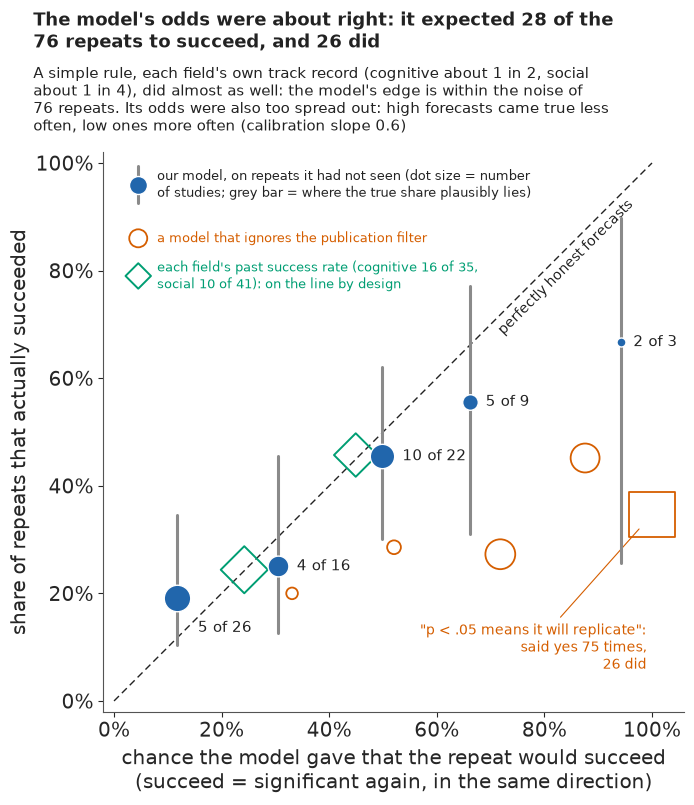

In [2]:
HOW_SURE = display(Markdown("**How sure are we.** *Filled in from the fits in part G.*"),
                   display_id=True)
HEADLINE = display(Markdown("*The headline figure is drawn in part G from the fits below and "
                            "appears here once the notebook has run.*"), display_id=True)

## The setting

Every science story rests on a quiet assumption: that the finding would come out the same way
if someone did the experiment again. In 2005 John Ioannidis argued ("Why most published research
findings are false", *PLoS Medicine*) that in fields with small studies, small effects and many
hypotheses, this assumption fails more often than not. Ten years later the **Reproducibility
Project: Psychology** tested it directly. The Open Science Collaboration (2015, *Science*), 270
researchers, repeated 100 experiments published in 2008 in three leading journals, with the
original materials, larger samples where possible and analysis plans fixed in advance. Of the 97
originals that reported a significant effect, 35 repeats were significant again; the repeated
effects were on average about half the size; and cognitive psychology fared about twice as well
as social psychology.

"A third replicated" is often read as "two thirds were false". That does not follow. A repeat
can fail because the original was a fluke, but also because the original was a real effect
reported at an inflated size, and a repeat sized for the inflated effect is too small to see the
true one. Both come from one mechanism: journals, reviewers and authors prefer results that
cross p = .05, so the **published** results are a filtered sample. Hedges (1992, *Statistical
Science*) wrote this filter into the likelihood as a step function of the p-value. It cannot be
learned from published results alone; Andrews & Kasy (2019, *American Economic Review*) showed
that **replications** identify it, because a repeat passes no filter, using exactly these data.

Etz & Vandekerckhove (2016, *PLoS ONE*) computed bias-corrected Bayes factors for each pair;
Johnson, Payne, Wang, Asher & Mandal (2017, *JASA*) fitted a null/real mixture and estimated
that about 90% of tested hypotheses in these journals were null; Gilbert, King, Pettigrew &
Wilson (2016, *Science*) replied to the project that a repeat is not a copy. The mixture of
Johnson et al., the filter of Hedges and of Andrews & Kasy, and the imperfect repeat of Gilbert
et al. become the three parts of our model.

The plan:

| part | question | tool |
|---|---|---|
| A | What did the project find, and which pairs can a model use? | 97 pairs, effective sample sizes, 76 claimed one-df effects |
| B | What does a publication filter do to what gets printed? | a toy world in NumPy |
| C | Can a null/real mixture explain the repeats on its own? | a marginalised two-class model (failure 1) |
| D | What if we write the filter into the likelihood? | a renormalised selection likelihood in closed form, checks, a prior predictive check |
| E | Can we trust its forecasts? | exact 10-fold track record against base rates (failure 2), field shares, an imperfect repeat, recovery, sensitivity |
| F | What should a news reader make of a new p-value? | the news reader's table and a risk ladder |
| G | How do we explain it to everyone? | a track-record plot, icon shelves, word strips, a GIF |

## A · 97 pairs, and the 76 we model

The project's master file has one row per study and 138 columns. `tools/build_e117_rpp.py`
keeps the 97 studies with a correlation effect size $r$ and a sample size for both the original
and the repeat (the project's own effect-size subset), and puts every effect on the **Fisher
z** scale, $z = \operatorname{atanh}(r)$, where a study's sampling noise is close to normal with
standard error $1/\sqrt{n - 3}$. Signs are aligned so that every original is positive; a repeat
with negative $z$ went the other way.

In [3]:
data.describe("e117_rpp_pairs")
RPP = data.load("e117_rpp_pairs")
print(RPP.shape)
print(RPP.groupby(["discipline", "journal"]).size().unstack(fill_value=0).to_string())

e117_rpp_pairs: One row per study with a correlation effect size and a sample size for both the original and the replication (97 rows): study, title, authors, journal (JPSP, PS, JEPLMC), discipline (Social or Cognitive), then per arm (_o original, _r replication): test, df1, df2, n, n_eff (df2 + 2 for t and F(1, df2) tests, else n), p (two-sided, recomputed by the OSC), r (correlation; r_r < 0 when the replication went the other way), z (Fisher z), se (1 / sqrt(n_eff - 3)); se_o_p (the original's se implied by its own recomputed p-value), p_o_reported (the p-value as the paper reported it), marginal_o (presented as .05 < p <= .10: only study 28 among the 76 used; three with a recomputed p just above .05 were reported as significant), single_df (both arms one-df tests: 79), claimed_effect (original p <= .10: all but studies 26, 89, 135), use (both: 76 pairs), success (replication p < .05 in the original's direction: 26 of the 76), osc_replicate (the OSC's own yes/no).
  source: Reproduc

Ninety-seven studies: 43 from cognitive psychology (most from *JEP: Learning, Memory and
Cognition*), 54 from social psychology (*JPSP* and *Psychological Science*).

### A data trap: how many observations is a test worth?

The file gives each study's number of participants $N$. For a between-subjects comparison the
standard error of $z$ is $1/\sqrt{N - 3}$. But the test a paper reports need not have as many
degrees of freedom as it has participants, in either direction: a test on a subset, after
exclusions or over items rather than people has fewer, and a test over trials has more. A cheap
check is to convert each effect back into a z-statistic, $z\sqrt{n - 3}$, and compare it with
the z-statistic the reported two-sided p-value implies, $\Phi^{-1}(1 - p/2)$. The ratio should
be about 1.

In [4]:
one_df = RPP[RPP["single_df"] & RPP["test_o"].isin(["t", "F"]) & (RPP["p_o"] > 0)]
z_from_p = stats.norm.isf(one_df["p_o"] / 2)
for lab, nn in (("participants N", one_df["n_o"]), ("df + 2 of the test", one_df["n_eff_o"])):
    ratio = one_df["z_o"] * np.sqrt(nn - 3) / z_from_p
    print(f"{lab:>20}: z-statistic / z from p, median {ratio.median():.3f}, "
          f"5-95% {ratio.quantile(0.05):.2f}-{ratio.quantile(0.95):.2f} "
          f"({len(ratio)} t and F tests)")
print(f"tests with fewer degrees of freedom + 2 than participants: "
      f"{int((one_df['n_eff_o'] < one_df['n_o']).sum())}, with more: "
      f"{int((one_df['n_eff_o'] > one_df['n_o']).sum())}")
print(RPP.loc[RPP["study"].isin([1, 112]),
              ["study", "test_o", "df1_o", "df2_o", "n_o", "n_eff_o", "p_o", "r_o"]].to_string(
    index=False))

      participants N: z-statistic / z from p, median 1.010, 5-95% 0.93-1.29 (70 t and F tests)
  df + 2 of the test: z-statistic / z from p, median 1.007, 5-95% 1.00-1.05 (70 t and F tests)
tests with fewer degrees of freedom + 2 than participants: 30, with more: 23
 study test_o  df1_o  df2_o   n_o  n_eff_o      p_o      r_o
     1      F    1.0   13.0  24.0     15.0 0.019395 0.594605
   112      F    1.0    9.0 141.0     11.0 0.016232 0.701089


With the head count most studies match, but a tail does not: the 5-95% range of the ratio runs
from 0.93 to 1.29. With $n_\text{eff} = \nu + 2$, the degrees of freedom of the test plus two,
the range shrinks to 1.00-1.05. Of the 70 tests, 30 have fewer degrees of freedom plus two than
participants and 23 have more; study 112 reports 141 participants and an $F(1, 9)$ test. The
build script therefore uses $n_\text{eff}$ for $t$ and $F$ tests and the head count only for
correlations, z and chi-square tests. For the original we go one step further and take its
standard error from its own recomputed p-value, $s_O = z_O / \Phi^{-1}(1 - p_O/2)$, so that its
z-statistic and its p-value agree exactly.

### Which pairs

Two kinds of study cannot enter a model of a *direction*. Eighteen originals report an $F$ test
with several numerator degrees of freedom (an interaction over many cells, say); their $r$ has no
sign, and "the repeat went the same way" has no meaning. And three originals reported a null or
non-significant result as their finding; our question is about claimed effects. That leaves 76.
A repeat **succeeds** when it is significant at .05 in the original's direction.

In [5]:
USE = RPP[RPP["use"]].reset_index(drop=True)
n = len(USE)
FIELDS = ["Cognitive", "Social"]
G = (USE["discipline"] == "Social").to_numpy().astype(int)  # 0 cognitive, 1 social
yR, sR = USE["z_r"].to_numpy(), USE["se_r"].to_numpy()
Y = USE["success"].to_numpy().astype(int)
MARG = USE["marginal_o"].to_numpy()  # presented to the journal as .05 < p <= .10
Z196, Z1645, Z258 = stats.norm.isf([0.025, 0.05, 0.005])
# The original's p as presented: the recomputed p, except that the three originals reported as
# significant with a recomputed p just above .05 are put just below it, so that the filter's
# band and the original's own z-statistic agree.
P_PRES = np.where(MARG | (USE["p_o"] < 0.05), USE["p_o"], 0.0499)
yO = USE["z_o"].to_numpy()
sO = yO / stats.norm.isf(P_PRES / 2)
SO_REC = USE["se_o_p"].to_numpy()  # from the recomputed p: an alternative coding in part E
print(f"one-df tests {int(RPP['single_df'].sum())} of {len(RPP)}, claimed effects "
      f"{int(RPP['claimed_effect'].sum())}, both: {n}")
print(f"repeats that succeeded: {Y.sum()} of {n} ({Y.mean():.0%}); "
      + ", ".join(f"{f.lower()} {Y[G == j].sum()} of {(G == j).sum()} ({Y[G == j].mean():.0%})"
                  for j, f in enumerate(FIELDS)))
print(f"success = repeat z-statistic above 1.96: agrees for {(Y == (yR / sR > Z196)).sum()} of {n}")
print(f"originals whose recomputed p is above .05: {int((USE['p_o'] >= 0.05).sum())}; as reported: "
      + ", ".join(f"study {r.study} p = {r.p_o:.4f} reported '{r.p_o_reported}'"
                  for r in USE[USE["p_o"] >= 0.05].itertuples())
      + f"; presented as .05 < p <= .10: {int(MARG.sum())}; standard error changed by "
      f"{np.abs(sO / SO_REC - 1).max():.1%} at most")
print(f"mean Fisher z: original {yO.mean():.2f}, repeat {yR.mean():.2f}; repeat larger than "
      f"original in {np.mean(yR > yO):.0%} of pairs; repeat in the other direction in "
      f"{np.mean(yR < 0):.0%}")
print(f"median effective n: original {USE['n_eff_o'].median():.0f}, "
      f"repeat {USE['n_eff_r'].median():.0f}")

one-df tests 79 of 97, claimed effects 94, both: 76
repeats that succeeded: 26 of 76 (34%); cognitive 16 of 35 (46%), social 10 of 41 (24%)
success = repeat z-statistic above 1.96: agrees for 76 of 76
originals whose recomputed p is above .05: 4; as reported: study 28 p = 0.0516 reported '<.06', study 37 p = 0.0509 reported '<.05', study 104 p = 0.0503 reported '0.05', study 129 p = 0.0514 reported 'prep = .92'; presented as .05 < p <= .10: 1; standard error changed by 0.7% at most
mean Fisher z: original 0.50, repeat 0.24; repeat larger than original in 13% of pairs; repeat in the other direction in 22%
median effective n: original 43, repeat 64


Of the 76 repeats, 26 succeeded (34%): 16 of 35 in cognitive psychology (46%) and 10 of 41 in
social psychology (24%). Four originals have a recomputed p a hair above .05 (.0503 to .0516),
but the filter acts on what the journal saw, and three of them were presented as significant:
"p = .05", "p < .05", and a "$p_\text{rep}$ = .92" (Killeen's replication probability, which
corresponds to p of about .047). Only study 28, reported as "p < .06", was presented as a
marginal result, so the model places it in the .05-.10 band and the other three below .05. For
those three we take the standard error from a p just below .05 (a change of under 1%), so that
the band and the original's own z-statistic agree; part E tries the other coding. The
repeats found effects about half as large as the originals (mean Fisher z 0.24 against 0.50),
came out larger in only about one pair in eight, and went the other way in about one in five,
although they were usually larger studies (median effective $n$ 64 against 43).

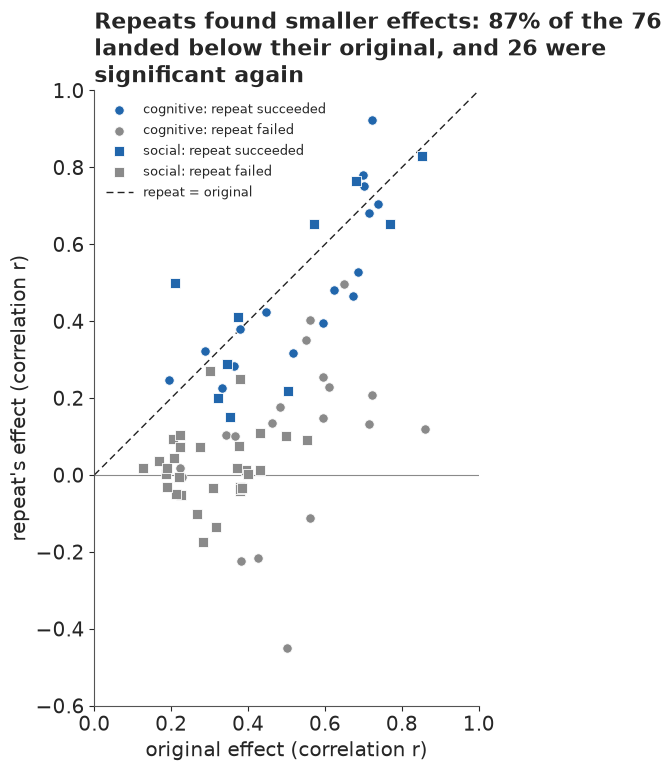

In [6]:
fig, ax = plt.subplots(figsize=(5.0, 7.6))
for j, (f, mk) in enumerate(zip(FIELDS, ("o", "s"))):
    for ok, col, lab in ((1, HI, "repeat succeeded"), (0, MUTED, "repeat failed")):
        m_ = (G == j) & (Y == ok)
        ax.scatter(np.tanh(yO[m_]), np.tanh(yR[m_]), marker=mk, s=46, color=col,
                   edgecolor="white", lw=0.6, label=f"{f.lower()}: {lab}", zorder=3)
ax.plot([0, 1], [0, 1], color=INK, lw=1, ls=(0, (5, 3)), label="repeat = original")
ax.axhline(0, color=MUTED, lw=0.8)
ax.set_xlim(0, 1)
ax.set_ylim(-0.6, 1)
ax.set_aspect("equal")
ax.set_xlabel("original effect (correlation r)")
ax.set_ylabel("repeat's effect (correlation r)")
ax.legend(loc="upper left", fontsize=9.5)
ax.set_title(wrap(f"Repeats found smaller effects: {np.mean(yR < yO):.0%} of the {n} landed below "
                  f"their original, and {Y.sum()} were significant again", 44), loc="left");

Nearly every point sits below the diagonal: regression to the mean, as for any selected sample.
Part B shows how much of it a filter can produce on its own.

## B · The filter in a toy world

Before fitting anything, a world where we know the truth. A thousand labs each test one
hypothesis with 40 participants. Half of the hypotheses are false (no effect at all); the other
half are real, with true effects $\theta \sim N(0.2, 0.1)$ on the Fisher scale, the size of a
typical psychology effect. Each lab publishes only if its result is significant in the predicted
direction. What does the published record look like, and how often would an exact repeat of a
published finding succeed?

In [7]:
tw = np.random.default_rng(2)
N_T, n_T = 1000, 40
s_T = 1 / np.sqrt(n_T - 3)
real_T = np.arange(N_T) < N_T // 2
theta_T = np.where(real_T, tw.normal(0.2, 0.1, N_T), 0.0)
y_T = tw.normal(theta_T, s_T)
pub_T = y_T / s_T >= Z196
power_T = stats.norm.sf(Z196 - theta_T / s_T)  # chance an exact repeat succeeds, given the truth
print(f"published {pub_T.sum()} of {N_T}; of them real {real_T[pub_T].sum()} "
      f"({real_T[pub_T].mean():.0%}), no effect {(~real_T[pub_T]).sum()}")
print(f"published: average effect found r = {np.tanh(y_T[pub_T]).mean():.2f}, their true "
      f"average r = {np.tanh(theta_T[pub_T]).mean():.2f}, a ratio of "
      f"{np.tanh(y_T[pub_T]).mean() / np.tanh(theta_T[pub_T]).mean():.2f}")
print(f"an exact repeat of a published finding succeeds {power_T[pub_T].mean():.0%} of the time "
      f"(real ones {power_T[pub_T & real_T].mean():.0%})")

published 122 of 1000; of them real 113 (93%), no effect 9
published: average effect found r = 0.40, their true average r = 0.24, a ratio of 1.64
an exact repeat of a published finding succeeds 37% of the time (real ones 39%)


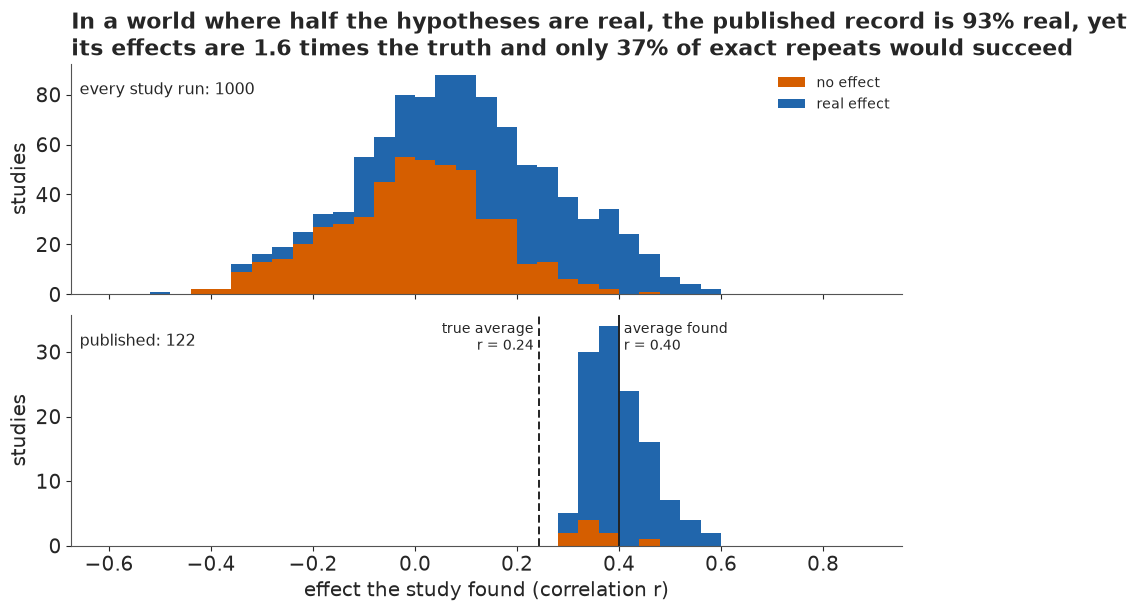

In [8]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
bins_T = np.arange(-0.6, 0.92, 0.04)
r_T = np.tanh(y_T)
for ax, sel, lab in ((a1, np.ones(N_T, bool), "every study run"), (a2, pub_T, "published")):
    ax.hist([r_T[sel & ~real_T], r_T[sel & real_T]], bins_T, stacked=True, color=[LO, HI],
            label=["no effect", "real effect"])
    ax.text(0.01, 0.92, f"{lab}: {sel.sum()}", transform=ax.transAxes, fontsize=11.5, va="top")
    ax.set_ylabel("studies")
f_avg, t_avg = r_T[pub_T].mean(), np.tanh(theta_T[pub_T]).mean()
a2.axvline(f_avg, color=INK, lw=1.4)
a2.axvline(t_avg, color=INK, lw=1.4, ls=(0, (4, 2)))
a2.text(f_avg + 0.01, a2.get_ylim()[1] * 0.85, f"average found\nr = {f_avg:.2f}", fontsize=10)
a2.text(t_avg - 0.01, a2.get_ylim()[1] * 0.85, f"true average\nr = {t_avg:.2f}", fontsize=10,
        ha="right")
a1.legend(loc="upper right", fontsize=10)
a2.set_xlabel("effect the study found (correlation r)")
a1.set_title(wrap(f"In a world where half the hypotheses are real, the published record is "
                  f"{real_T[pub_T].mean():.0%} real, yet its effects are {f_avg / t_avg:.1f} times "
                  f"the truth and only {power_T[pub_T].mean():.0%} of exact repeats would succeed",
                  84), loc="left");

Only about one study in eight makes it into print, and 93% of those are real effects; the filter
keeps nulls out well. But the published effects average r = 0.40 where their truth is 0.24,
because a 40-person study of a small effect is only significant when its noise pushes it up. An
exact repeat has the power of the *true* effect, so only about 37% of repeats succeed although
almost every finding is real. That is the lesson of the whole notebook: **a low replication rate
does not mean the findings were false, and a high share of real findings does not mean they
will replicate**. Telling the two apart takes a model that knows about the filter and sees the
repeats.

## C · A mixture without the filter

### Two looks at one effect

For pair $k$, let $c_k$ say whether the hypothesis is real ($c_k = 1$, probability $\pi$) or not.
A real hypothesis has a true effect $\theta_k \sim N(\mu, \tau)$; a false one has $\theta_k = 0$.
The original and the repeat are two noisy looks at the same $\theta_k$:

$$ y_{O,k} \sim N(\theta_k, s_{O,k}), \qquad y_{R,k} \sim N(\theta_k, s_{R,k}). $$

Both latent quantities can be integrated out in closed form. For the null class the two are
independent normals around 0. For the real class $(y_O, y_R)$ is bivariate normal with means
$\mu$, variances $\tau^2 + s^2$ and covariance $\tau^2$, which we write as the original's
marginal times the repeat given the original:

$$ y_O \sim N\big(\mu, \sqrt{\tau^2 + s_O^2}\big), \qquad
   y_R \mid y_O \sim N\Big(m, \sqrt{v + s_R^2}\Big), \quad
   m = \mu + \tfrac{\tau^2}{\tau^2 + s_O^2}(y_O - \mu),\
   v = \tfrac{\tau^2 s_O^2}{\tau^2 + s_O^2}. $$

The pair's likelihood is the two classes mixed with `logaddexp`. A data `mask` multiplies the
repeat's term, so that the same compiled model can later hide some repeats. Every data array is
a `pm.Data`, so one compilation serves a fit, ten cross-validation folds and a simulation.
The functions take `xp` (NumPy or PyTensor) so that the same code makes predictions in NumPy.

In [9]:
SQ2 = np.sqrt(2.0)


def ncdf(x, xp=np):
    return 0.5 * (pt.erfc if xp is pt else special.erfc)(-x / SQ2)


def nlogpdf(y, m, s, xp=np):
    return -0.5 * ((y - m) / s) ** 2 - xp.log(s) - 0.5 * np.log(2 * np.pi)


def p_published(mz, sz, w_marg, w_sig=1.0, xp=np):
    """P(published) for an original whose z-statistic is N(mz, sz): weight 1 below p = .01,
    w_sig for .01-.05 (1 unless a model gives it its own step), w_marg for .05-.10, 0 above."""
    F = lambda c: ncdf((c - mz) / sz, xp)  # noqa: E731
    return (1 - F(Z258)) + w_sig * (F(Z258) - F(Z196)) + w_marg * (F(Z196) - F(Z1645))


def pair_loglik(p, yO, sO, yR, sR, mask, in_marg, in_mid, xp=np, selection=True):
    """Per-pair log-likelihood of a published original and (where mask = 1) its repeat."""
    pi, mu, tau = p["pi"], p["mu"], p["tau"]
    lam, t_rep = p.get("lam", 1.0), p.get("tau_rep", 0.0)
    sRr = xp.sqrt(sR**2 + t_rep**2)  # between-site spread: real effects only
    ln_null = nlogpdf(yO, 0.0, sO, xp) + mask * nlogpdf(yR, 0.0, sR, xp)
    v1 = tau**2 + sO**2
    cm = lam * (mu + tau**2 / v1 * (yO - mu))
    cs = xp.sqrt(lam**2 * tau**2 * sO**2 / v1 + sRr**2)
    ln_real = nlogpdf(yO, mu, xp.sqrt(v1), xp) + mask * nlogpdf(yR, cm, cs, xp)
    mix = xp.logaddexp(xp.log1p(-pi) + ln_null, xp.log(pi) + ln_real)
    if not selection:
        return mix
    w_marg, w_sig = p["w_marg"], p.get("w_sig", 1.0)
    logw = in_marg * xp.log(w_marg) + in_mid * xp.log(w_sig)
    A0 = p_published(0.0, 1.0, w_marg, w_sig, xp)
    A1 = p_published(mu / sO, xp.sqrt(v1) / sO, w_marg, w_sig, xp)
    return logw + mix - xp.log((1 - pi) * A0 + pi * A1)


def bands(so):
    """The filter's band of each original, from its own z-statistic: one scale for the weight
    in the numerator and for the probability of publication in the denominator."""
    z = yO / so
    return dict(in_marg=((z >= Z1645) & (z < Z196)).astype(float),
                in_mid=((z >= Z196) & (z < Z258)).astype(float))


Z_O = yO / sO
DATA0 = dict(yO=yO, sO=sO, yR=yR, sR=sR, mask=np.ones(n), **bands(sO))
assert (DATA0["in_marg"] == MARG).all() and (Z_O >= Z1645).all()
PRIORS = dict(pi=(1.0, 1.0), mu=(0.2, 0.2), tau=0.3, w_marg=(2.0, 2.0), lam=(4.0, 2.0),
              tau_rep=0.1, w_sig=(2.0, 2.0))


def build(selection=True, by_field=False, repeat=False, cut3=False, priors=None, data=None):
    pr = {**PRIORS, **(priors or {})}
    with pm.Model(coords={"pair": np.arange(n), "field": FIELDS}) as m:
        d = {k: pm.Data(k, v, dims="pair") for k, v in {**DATA0, **(data or {})}.items()}
        if by_field:
            pi = pm.Beta("pi", *pr["pi"], dims="field")[G]
        else:
            pi = pm.Beta("pi", *pr["pi"])
        p = dict(pi=pi, mu=pm.Normal("mu", *pr["mu"]), tau=pm.HalfNormal("tau", pr["tau"]))
        if repeat:
            p["lam"] = pm.Beta("lam", *pr["lam"])
            p["tau_rep"] = pm.HalfNormal("tau_rep", pr["tau_rep"])
        if selection:
            p["w_marg"] = pm.Beta("w_marg", *pr["w_marg"])
            if cut3:
                p["w_sig"] = pm.Beta("w_sig", *pr["w_sig"])
        ll = pair_loglik(p, d["yO"], d["sO"], d["yR"], d["sR"], d["mask"], d["in_marg"],
                         d["in_mid"], xp=pt, selection=selection)
        pm.Potential("lik", ll.sum())
    return m

The helpers below sample a compiled model (4 chains, 400 tuning and 1,000 kept draws each, the
nutpie defaults), report its diagnostics in one line, and turn posterior draws into two
predictions per pair: the chance the original is real given its own result, and the chance a
repeat succeeds, $P(y_R / s_R > 1.96 \mid y_O)$, which for the real class is a normal tail
probability under the conditional distribution above.

In [10]:
def sample(comp, seed, **dat):
    c = comp.with_data(**{k: np.asarray(v, float) for k, v in dat.items()}) if dat else comp
    return nutpie.sample(c, chains=4, tune=400, draws=1000, seed=seed, progress_bar=False)


def flat(tr):
    out = {}
    for k in tr.posterior.data_vars:
        v = tr.posterior[k].values
        out[k] = v.reshape(-1) if v.ndim == 2 else v.reshape(-1, v.shape[-1])
    return out


def health(tr):
    div = int(tr.sample_stats["diverging"].sum())
    rh = max(float(az.rhat(tr.posterior[v]).max()) for v in tr.posterior.data_vars)
    ess = min(float(az.ess(tr.posterior[v]).min()) for v in tr.posterior.data_vars)
    return div, rh, ess


def fit(comp, label, seed=RANDOM_SEED, **dat):
    t0 = time.time()
    tr = sample(comp, seed, **dat)
    TIMES[label] = time.time() - t0
    div, rh, ess = health(tr)
    print(f"{label}: {TIMES[label]:.1f} s, {div} divergences, max r_hat {rh:.3f}, "
          f"min bulk ESS {ess:.0f}")
    return tr


def predict(post, gi, yo, so, sr, yr=None):
    """Per draw x pair: P(real | original), P(repeat succeeds | original) [, with the repeat]."""
    S = len(post["mu"])

    def col(k, default):
        v = post.get(k)
        if v is None:
            return np.full((S, 1), default)
        return v[:, gi] if v.ndim == 2 else v[:, None]

    pi, mu, tau, lam, t_rep = (col("pi", 0.5), col("mu", 0.0), col("tau", 1.0), col("lam", 1.0),
                               col("tau_rep", 0.0))
    sRr = np.sqrt(sr**2 + t_rep**2)
    v1 = tau**2 + so**2
    lr = (np.log(pi) - np.log1p(-pi) + stats.norm.logpdf(yo, mu, np.sqrt(v1))
          - stats.norm.logpdf(yo, 0.0, so))
    p_real = special.expit(lr)
    cm = lam * (mu + tau**2 / v1 * (yo - mu))
    cs = np.sqrt(lam**2 * tau**2 * so**2 / v1 + sRr**2)
    out = dict(p_real=p_real, p_succ=p_real * stats.norm.sf((Z196 * sr - cm) / cs)
               + (1 - p_real) * stats.norm.sf(Z196))
    if yr is not None:
        l1, l0 = stats.norm.logpdf(yr, cm, cs), stats.norm.logpdf(yr, 0.0, sr)
        out["p_real_both"] = special.expit(lr + l1 - l0)
        out["ll_rep"] = np.logaddexp(np.log1p(-p_real) + l0, np.log(p_real) + l1)
    return out


def show(tr, names):
    s = az.summary(tr, var_names=names, round_to=3)
    print(s[["mean", "sd", "eti89_lb", "eti89_ub", "ess_bulk", "r_hat"]].to_string())

### Failure 1: taking the published record at face value

The first model is the mixture alone, with $\pi \sim \text{Beta}(1, 1)$,
$\mu \sim N(0.2, 0.2)$ and $\tau \sim \text{HalfNormal}(0.3)$. It treats the 76 published
originals as if they were a fair sample of all the experiments that were run.

In [11]:
t0 = time.time()
C_NAIVE = nutpie.compile_pymc_model(build(selection=False))
TIMES["compile naive"] = time.time() - t0
TR_NAIVE = fit(C_NAIVE, "naive mixture")
show(TR_NAIVE, ["pi", "mu", "tau"])
P_NAIVE = flat(TR_NAIVE)
PR_NAIVE = predict(P_NAIVE, G, yO, sO, sR)
print(f"expected successful repeats, in-sample: {PR_NAIVE['p_succ'].mean(0).sum():.0f} "
      f"(observed {Y.sum()})")

naive mixture: 0.1 s, 0 divergences, max r_hat 1.002, min bulk ESS 1644
      mean     sd  eti89_lb  eti89_ub  ess_bulk  r_hat
pi   0.921  0.056     0.819     0.992  1644.261  1.000
mu   0.344  0.036     0.286     0.403  2379.089  1.001
tau  0.255  0.028     0.214     0.303  3055.999  1.002
expected successful repeats, in-sample: 56 (observed 26)


The fit is clean and its answer confident: 92% of hypotheses real (89% interval 82-99%), with a
typical true effect of 0.34 on the Fisher scale (r about 0.33), spread by 0.25. Those are the
published effects, read as the truth. A real effect of that size with the repeats' sample sizes
would be detected most of the time, so the model expects about 56 of the 76 repeats to succeed,
more than twice the 26 that did, even while scoring itself on the repeats it was fitted to. What
part B's toy world produced by selection, this model must explain as bad luck.

## D · Writing the filter into the likelihood

### The selected density

Let $Z_O = y_O / s_O$ be the original's z-statistic and $w(Z_O)$ the relative chance that a
result in its p-value band reaches print: 1 for $p < .05$ (only ratios of weights are
identified, so one is fixed), $w_\text{marg}$ for $.05 \le p < .10$, and 0 above $.10$. The zero
is not an estimate: the sample is *defined* as published claims of an effect. The density of a
published pair is the unfiltered density, reweighted and renormalised:

$$ f(y_O, y_R \mid \text{published}) =
   \frac{w(Z_O)\,\big[(1 - \pi)\, p_0(y_O, y_R) + \pi\, p_1(y_O, y_R)\big]}
        {(1 - \pi)\, A_0 + \pi\, A_1(s_O)}. $$

The denominator is the probability that a study with this precision gets published at all. It
is a sum of normal probabilities over the bands. For the null class $Z_O \sim N(0, 1)$; for the
real class, averaging over $\theta \sim N(\mu, \tau)$, $Z_O \sim N\big(\mu/s_O,
\sqrt{\tau^2 + s_O^2}/s_O\big)$, so

$$ A_1(s_O) = \Big[1 - \Phi\Big(\tfrac{1.96\, s_O - \mu}{\sqrt{\tau^2 + s_O^2}}\Big)\Big]
   + w_\text{marg}\Big[\Phi\Big(\tfrac{1.96\, s_O - \mu}{\sqrt{\tau^2 + s_O^2}}\Big)
   - \Phi\Big(\tfrac{1.645\, s_O - \mu}{\sqrt{\tau^2 + s_O^2}}\Big)\Big]. $$

The integral of a normal CDF against a normal density is again a normal CDF, so no quadrature
is needed. The weight in the numerator and the bands in the denominator must be read from the
same $Z_O$, or the density no longer integrates to one; that is why part A put the three
originals presented as significant just below .05. The repeat is not renormalised: it passed no
filter. This is the **population** form of the selection model, the form Andrews & Kasy use:
each study's denominator depends only on its precision.

### What the filter does, and what it does not

For one study with known $\pi$, $\mu$ and $\tau$, the chance that it is real given its original
result is

$$ P(\text{real} \mid y_O) = \frac{\pi\, p_1(y_O)}{(1 - \pi)\, p_0(y_O) + \pi\, p_1(y_O)}, $$

and the factor $w(Z_O)$ and the denominator cancel: every study in the sample has already
passed the filter. So the filter does not change how we read one study given the population. It
changes **which population we learn**: $\pi$, $\mu$ and $\tau$ now describe all the experiments
that were run, not the ones that were printed.

### Two checks before sampling

A new likelihood deserves a unit test (E32). The first check compares the closed form, with
every term switched on, against brute-force integration over $\theta$ and over the original's
result, for three pairs; the second compares the PyTensor graph with the NumPy version.

In [12]:
P_CHK = dict(pi=0.4, mu=0.1, tau=0.35, w_marg=0.2, tau_rep=0.12, lam=0.8)


def w_(z):
    return 1.0 if z >= Z196 else (P_CHK["w_marg"] if z >= Z1645 else 0.0)


def brute_force(k_):
    """log f(y_O, y_R | published) for pair k_ by numerical integration, the weight taken from
    the original's own z-statistic."""
    yo_, so_, yr_, sr_ = yO[k_], sO[k_], yR[k_], sR[k_]
    srr_ = np.hypot(sr_, P_CHK["tau_rep"])
    num_real = integrate.quad(lambda t: stats.norm.pdf(t, P_CHK["mu"], P_CHK["tau"])
                              * stats.norm.pdf(yo_, t, so_)
                              * stats.norm.pdf(yr_, P_CHK["lam"] * t, srr_), -4, 4)[0]
    num_null = stats.norm.pdf(yo_, 0, so_) * stats.norm.pdf(yr_, 0, sr_)
    A_ = lambda t: integrate.quad(lambda y: w_(y / so_) * stats.norm.pdf(y, t, so_),  # noqa
                                  -6, 6, points=[Z1645 * so_, Z196 * so_])[0]
    den_ = ((1 - P_CHK["pi"]) * A_(0.0) + P_CHK["pi"] * integrate.quad(
        lambda t: stats.norm.pdf(t, P_CHK["mu"], P_CHK["tau"]) * A_(t), -3, 3)[0])
    return np.log(w_(yo_ / so_) * ((1 - P_CHK["pi"]) * num_null + P_CHK["pi"] * num_real) / den_)


# an ordinary pair, the one marginal original (study 28) and one of the three reported as
# significant with a recomputed p just above .05 (study 37)
for k_ in (5, *np.where(USE["study"].isin([28, 37]))[0]):
    closed = pair_loglik(P_CHK, *(DATA0[k][k_] for k in ("yO", "sO", "yR", "sR", "mask",
                                                         "in_marg", "in_mid")))
    print(f"pair {k_} (study {USE['study'][k_]}, z = {Z_O[k_]:.3f}): brute force "
          f"{brute_force(k_):.10f}, closed form {closed:.10f}")

M_CHK = build(by_field=True, repeat=True)
names_ = ["pi", "mu", "tau", "lam", "tau_rep", "w_marg"]
outs_ = M_CHK.replace_rvs_by_values([M_CHK["lik"]] + [M_CHK[v] for v in names_])
f_chk = pytensor.function(M_CHK.value_vars, outs_, on_unused_input="ignore")
vals = f_chk(**M_CHK.initial_point())
pt_ = dict(zip(names_, vals[1:]))
pt_["pi"] = pt_["pi"][G]
print(f"model graph {float(vals[0]):.10f}, NumPy "
      f"{pair_loglik(pt_, *(DATA0[k] for k in DATA0)).sum():.10f}")

pair 5 (study 6, z = 3.137): brute force 0.6935367374, closed form 0.6935367374


pair 15 (study 28, z = 1.947): brute force 0.4405761280, closed form 0.4405761280
pair 20 (study 37, z = 1.961): brute force 1.2913330945, closed form 1.2913330945


model graph 31.6332567531, NumPy 31.6332567531


For all three pairs, an ordinary one, the marginal original and one presented as significant at
a recomputed p just above .05, the closed form matches the brute force to the last printed
digit, and so does the model graph. (Evaluating a model expression with `compile_fn` would have
drawn the random variables instead of using their values; `replace_rvs_by_values` is the safe
route, as E19 found.)

### Priors, and a weight the prior predictive check fixes

The first filter model keeps the naive model's priors and adds $w_\text{marg} \sim
\text{Beta}(2, 2)$. A `pm.Potential` likelihood cannot be forward-sampled by PyMC, so the prior
predictive check is written in NumPy: for each prior draw, each of the 76 slots is filled by
drawing studies at that slot's precision until one passes the filter, and its repeat is drawn
without one. We run it twice, once with the weight above $p = .10$ fixed at zero and once with
it free, $w_\text{ns} \sim \text{Beta}(1, 4)$, a prior that seems to say "non-significant
results are rarely published".

In [13]:
pp = np.random.default_rng(3)
D_PP, C_PP = 1000, 60
pi_p, mu_p = pp.beta(1, 1, D_PP), pp.normal(0.2, 0.2, D_PP)
tau_p, wm_p = np.abs(pp.normal(0, 0.3, D_PP)), pp.beta(2, 2, D_PP)
rows = []
for lab, wn_p in (("w = 0 above p = .10", np.zeros(D_PP)),
                  ("w ~ Beta(1, 4) above p = .10", pp.beta(1, 4, D_PP))):
    real_p = pp.random((D_PP, n, C_PP)) < pi_p[:, None, None]
    th_p = np.where(real_p, pp.normal(mu_p[:, None, None], tau_p[:, None, None], (D_PP, n, C_PP)),
                    0.0)
    yo_p = pp.normal(th_p, sO[None, :, None])
    z_p = yo_p / sO[None, :, None]
    w_p = np.where(z_p >= Z196, 1.0, np.where(z_p >= Z1645, wm_p[:, None, None],
                                              wn_p[:, None, None]))
    acc = pp.random((D_PP, n, C_PP)) < w_p
    first = acc.argmax(-1)
    take = lambda a: np.take_along_axis(a, first[..., None], -1)[..., 0]  # noqa: E731
    yo1, th1 = take(yo_p), take(th_p)
    full_ = acc.any(-1).all(1)  # draws in which every slot published within C_PP tries
    yr1 = pp.normal(th1, sR[None, :])
    stat = {"successful repeats": (yr1 / sR > Z196).sum(1),
            "originals with p above .05": (yo1 / sO < Z196).sum(1),
            "mean original z": yo1.mean(1), "mean repeat z": yr1.mean(1)}
    obs = {"successful repeats": Y.sum(), "originals with p above .05": int((Z_O < Z196).sum()),
           "mean original z": yO.mean(), "mean repeat z": yR.mean()}
    for k, v in stat.items():
        v = v[full_]
        q5, q50, q95 = np.quantile(v, [0.05, 0.5, 0.95])
        rows.append(dict(prior=lab, statistic=k, q5=round(q5, 2), median=round(q50, 2),
                         q95=round(q95, 2), observed=round(float(obs[k]), 2),
                         share_below=round(float(np.mean(v <= obs[k])), 2)))
    print(f"{lab}: {full_.mean():.0%} of prior draws publish all 76 slots within {C_PP} tries")
del real_p, th_p, yo_p, z_p, w_p, acc
print(pd.DataFrame(rows).to_string(index=False))

w = 0 above p = .10: 69% of prior draws publish all 76 slots within 60 tries


w ~ Beta(1, 4) above p = .10: 97% of prior draws publish all 76 slots within 60 tries
                       prior                  statistic    q5  median   q95  observed  share_below
         w = 0 above p = .10         successful repeats 23.35   52.00 67.00     26.00         0.07
         w = 0 above p = .10 originals with p above .05  1.00    7.00 20.00      1.00         0.08
         w = 0 above p = .10            mean original z  0.39    0.53  0.76      0.50         0.38
         w = 0 above p = .10              mean repeat z  0.14    0.40  0.70      0.24         0.17
w ~ Beta(1, 4) above p = .10         successful repeats  2.00   29.00 60.00     26.00         0.46
w ~ Beta(1, 4) above p = .10 originals with p above .05  7.00   38.00 70.00      1.00         0.00
w ~ Beta(1, 4) above p = .10            mean original z -0.01    0.26  0.62      0.50         0.84
w ~ Beta(1, 4) above p = .10              mean repeat z -0.04    0.19  0.57      0.24         0.59


With the weight fixed at zero the prior predictive distribution covers what we observed on all
four statistics, though three of them sit low: 26 successes (the prior's median is 52; 26 is at
its 7th percentile), one original with p above .05 (median 7; 8th percentile) and a mean repeat
z of 0.24 (17th percentile). A prior that takes published effects at their word expects repeats
to succeed, and the data will have to pull it down. With a free weight above .10 the prior
expects a median of 38 of the 76 originals to be non-significant, against one in the data, and
fewer than 1 prior draw in 100 has as few. A weight for results we have defined out of the
sample is not a parameter of this data set, so it stays at zero. About 3 in 10 prior draws with
the fixed weight do not fill all 76 slots within 60 tries (worlds in which significant results
are rare) and are left out of the table.

### Fitting the filter

The first filter model has one share $\pi$ for every study, as the naive model did.

In [14]:
t0 = time.time()
C_SHARED = nutpie.compile_pymc_model(build(selection=True))
TIMES["compile filter"] = time.time() - t0
TR_SHARED = fit(C_SHARED, "filter, one shared share")
show(TR_SHARED, ["pi", "mu", "tau", "w_marg"])
P_SHARED = flat(TR_SHARED)


def share_published(post, sel, so=sO):
    """Per draw: the share of real effects among published studies with the precisions of `sel`."""
    S = len(post["mu"])
    pi = post["pi"][:, G[sel]] if post["pi"].ndim == 2 else post["pi"][:, None]
    wm, ws = post["w_marg"][:, None], post.get("w_sig", np.ones(S))[:, None]
    s_ = so[None, sel]
    A0 = p_published(0.0, 1.0, wm, ws)
    A1 = p_published(post["mu"][:, None] / s_, np.sqrt(post["tau"][:, None] ** 2 + s_**2) / s_,
                     wm, ws)
    return (pi * A1 / (pi * A1 + (1 - pi) * A0)).mean(1)


SH_SHARED = share_published(P_SHARED, np.ones(n, bool))
PR_SHARED = predict(P_SHARED, G, yO, sO, sR)
print(f"share real among published: {SH_SHARED.mean():.2f} "
      f"({np.quantile(SH_SHARED, 0.055):.2f}-{np.quantile(SH_SHARED, 0.945):.2f})")
print(f"expected successful repeats, in-sample: {PR_SHARED['p_succ'].mean(0).sum():.0f} "
      f"(observed {Y.sum()})")

filter, one shared share: 0.3 s, 0 divergences, max r_hat 1.002, min bulk ESS 1517
         mean     sd  eti89_lb  eti89_ub  ess_bulk  r_hat
pi      0.119  0.058     0.051     0.227  1702.765  1.001
mu      0.021  0.151    -0.231     0.250  1516.634  1.001
tau     0.411  0.063     0.317     0.517  2028.650  1.002
w_marg  0.075  0.045     0.021     0.157  3184.637  1.000
share real among published: 0.53 (0.41-0.65)
expected successful repeats, in-sample: 32 (observed 26)


The picture changes completely. Before the filter, only about one hypothesis in eight is real
($\pi$ about 0.12), and real effects are centred near zero with a wide spread ($\tau$ about 0.4):
many small effects and a few large ones. The centre is a shape, not a statement about direction:
every original is signed by its own result, and part E finds that a slab leaning positive fits
exactly as well. A result between .05 and .10 reaches print about a thirteenth as often as a
significant one ($w_\text{marg}$ about 0.08), a number that rests on the single marginal original
and the prior. Among *published* findings about half are real (41-65%), because the filter
enriches them, and the model now expects about 32 successful repeats in-sample instead of 56.

## E · Can we trust it? The track record

### Scoring forecasts on repeats the model has not seen

The test is the one the public would ask for: hide some repeats, forecast them, and compare with
what happened. We cut the 76 pairs into 10 folds at random. For each fold the model sees every
original and the other folds' repeats, then forecasts $P(\text{success})$ for the hidden ones.
Setting the fold's `mask` to 0 removes exactly those repeat terms, and nutpie's
`compiled.with_data(mask=...)` swaps it without recompiling.

Four numbers score the 76 held-out forecasts $p_k$ against outcomes $y_k$: the **Brier score**
$\frac{1}{n}\sum (p_k - y_k)^2$ (lower is better); the **log score**
$\frac{1}{n}\sum [y_k \log p_k + (1 - y_k)\log(1 - p_k)]$ (higher is better, and harsh on
confident misses); the **expected number of successes** $\sum p_k$ against the observed 26; and
the **AUC**, the chance that a random success was given a higher forecast than a random failure.
A forecast has to beat simple rules to be worth anything. The plainest is the base rate, "about
1 in 3 replicate", learned from the training folds; a stronger one is the base rate of the
study's own field.

In [15]:
FOLDS = np.random.default_rng(117).permutation(n) % 10


def track_record(comp, label, seed0=1000, so=sO):
    t0 = time.time()
    p_cv, divs, rh = np.zeros(n), 0, 1.0
    for f in range(10):
        h = FOLDS == f
        tr = sample(comp, seed0 + f, mask=(~h).astype(float))
        d_, r_, _ = health(tr)
        divs, rh = divs + d_, max(rh, r_)
        p_cv[h] = predict(flat(tr), G[h], yO[h], so[h], sR[h])["p_succ"].mean(0)
    TIMES[f"10-fold {label}"] = time.time() - t0
    print(f"10-fold, {label}: {TIMES[f'10-fold {label}']:.0f} s, {divs} divergences in 10 fits, "
          f"max r_hat {rh:.3f}")
    return p_cv


def scores(p, y=Y):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    pos, neg = p[y == 1], p[y == 0]
    auc = (pos[:, None] > neg[None, :]).mean() + 0.5 * (pos[:, None] == neg[None, :]).mean()
    return dict(brier=np.mean((p - y) ** 2), log_score=np.mean(y * np.log(p)
                + (1 - y) * np.log1p(-p)), expected=p.sum(), observed=int(y.sum()), auc=auc)


CV = {}
CV["base rate (training folds)"] = np.array([Y[FOLDS != f].mean() for f in FOLDS])
CV["field base rate (training folds)"] = np.array(
    [Y[(FOLDS != FOLDS[i]) & (G == G[i])].mean() for i in range(n)])
CV["naive mixture"] = track_record(C_NAIVE, "naive mixture")
CV["filter, one shared share"] = track_record(C_SHARED, "filter, one shared share")


def score_table(keys):
    t = pd.DataFrame({k: scores(CV[k]) for k in keys}).T.astype(float)
    t.loc[t.index.str.contains("base rate"), "auc"] = np.nan  # see the note below the table
    return t.round(3)


print(score_table(CV).to_string())
FIELD_RATE = np.where(G == 0, Y[G == 0].mean(), Y[G == 1].mean())
print(f"AUC of the field base rate fitted to all 76 (in-sample): {scores(FIELD_RATE)['auc']:.2f}")

10-fold, naive mixture: 1 s, 0 divergences in 10 fits, max r_hat 1.005


10-fold, filter, one shared share: 3 s, 0 divergences in 10 fits, max r_hat 1.005
                                  brier  log_score  expected  observed    auc
base rate (training folds)        0.234     -0.662    25.974      26.0    NaN
field base rate (training folds)  0.227     -0.648    25.650      26.0    NaN
naive mixture                     0.383     -1.201    56.138      26.0  0.618
filter, one shared share          0.235     -0.796    31.843      26.0  0.620
AUC of the field base rate fitted to all 76 (in-sample): 0.62


The refits are healthy: no divergences in the 20 fits, r_hat at most 1.005. Ignoring the filter
is a disaster out of sample: the naive mixture expects about 56 successes where 26 happened, and
its log score, about -1.2, is far below the base rate's -0.66. The AUC is blank for the base
rates because their out-of-fold forecasts differ only by which folds they came from, an artefact;
fitted to all 76 at once, the field base rate ranks with an AUC of about 0.62.

### Failure 2: losing to "about 1 in 3"

Writing the filter in brings the expected count down to about 32, and yet the filter model
**loses to the plain base rate** on the log score (about -0.80 against -0.66) and only ties it on
Brier. A forecaster who said "34%" every time would have done better, and the field base rate,
"46% for cognitive, 24% for social", better still (-0.65). The model is missing something; two
diagnostics say what:

In [16]:
p_sh = CV["filter, one shared share"]
for j, f in enumerate(FIELDS):
    m_ = G == j
    print(f"{f:>9}: forecast {p_sh[m_].sum():.1f} successes, observed {Y[m_].sum()} "
          f"of {m_.sum()}")
strong = PR_SHARED["p_real"].mean(0) > 0.9
tau2, mu_ = P_SHARED["tau"][:, None] ** 2, P_SHARED["mu"][:, None]
m_rep = mu_ + tau2 / (tau2 + sO**2) * (yO - mu_)  # per draw: the repeat's mean if real
v_rep = tau2 * sO**2 / (tau2 + sO**2) + sR**2  # and its variance
sd_rep = np.sqrt(v_rep.mean(0) + m_rep.var(0))
z_rep = (yR - m_rep.mean(0)) / sd_rep
print(f"{strong.sum()} originals the model calls real (> 90%): their repeats' mean z "
      f"{yR[strong].mean():.2f}, the model's expected mean {m_rep.mean(0)[strong].mean():.2f}; "
      f"standardised misses: mean {z_rep[strong].mean():.2f}, sd {z_rep[strong].std():.2f} "
      "(0 and 1 if the model were right)")

Cognitive: forecast 15.3 successes, observed 16 of 35
   Social: forecast 16.6 successes, observed 10 of 41
15 originals the model calls real (> 90%): their repeats' mean z 0.39, the model's expected mean 0.57; standardised misses: mean -0.96, sd 1.67 (0 and 1 if the model were right)


One share for every study gets cognitive psychology right (about 15 successes forecast, 16
observed) and overshoots social psychology by about 6 (16.6 against 10), the contrast the Open
Science Collaboration reported; cognitive designs are more often within-subject and better
powered, and their hypotheses may be more often true. And the 15 originals the model is surest
are real have repeats smaller than it expects (mean z 0.39 against 0.57, about one predictive sd
too low), scattered by two thirds more than it allows. That is the point of Gilbert et al.
(2016): a repeat is a new study, in a new lab, and may see a weaker version of the effect.

### Two extensions, chosen after seeing the track record

We add both, and **we added them after seeing the first track record**: with 76 pairs, that
flatters the second track record somewhat, so its scores are the best case for this model, not
an independent test.

The first is **a share for each field**, $\pi_\text{cognitive}$ and $\pi_\text{social}$, each
$\text{Beta}(1, 1)$, while effect sizes and the filter stay shared. The second is **an imperfect
repeat**: the repeat of a real effect sees a fraction $\lambda$ of it plus a between-site spread
$\tau_\text{rep}$, $y_R \sim N\big(\lambda\theta, \sqrt{s_R^2 + \tau_\text{rep}^2}\big)$, with
$\lambda \sim \text{Beta}(4, 2)$ (most repeats see most of the effect) and $\tau_\text{rep} \sim
\text{HalfNormal}(0.1)$. In the closed form $m$ becomes $\lambda m$ and the repeat's variance
$\lambda^2 v + s_R^2 + \tau_\text{rep}^2$.

$\lambda$ below 1 covers changes of population, setting and procedure as well as any inflation
the step filter does not capture. The spread belongs to real effects only: an effect that is
zero is zero at every site, so the repeat of a null stays $N(0, s_R)$ and succeeds 1 time in 40,
the false-positive rate of the test. Giving nulls the spread too would let a "no effect" finding
succeed more often the larger its repeat, as a large repeat detected site effects that are not
the finding at all.

In [17]:
t0 = time.time()
C_FULL = nutpie.compile_pymc_model(build(selection=True, by_field=True, repeat=True))
TIMES["compile full"] = time.time() - t0
TR_FULL = fit(C_FULL, "filter + field shares + imperfect repeat")
show(TR_FULL, ["pi", "mu", "tau", "lam", "tau_rep", "w_marg"])
P_FULL = flat(TR_FULL)
CV["filter + field + imperfect repeat"] = track_record(C_FULL, "full model")
print(score_table(CV).to_string())


def paired(a, b, y=Y):
    """Mean per-study score difference a - b over the 76 held-out forecasts, and its
    standard error."""
    pa, pb = (np.clip(CV[k], 1e-6, 1 - 1e-6) for k in (a, b))
    out = {}
    for name, d in (("Brier", (pa - y) ** 2 - (pb - y) ** 2),
                    ("log score", y * np.log(pa / pb) + (1 - y) * np.log((1 - pa) / (1 - pb)))):
        out[name] = (d.mean(), d.std(ddof=1) / np.sqrt(len(d)))
    return out


for b in ("base rate (training folds)", "field base rate (training folds)"):
    print(f"full model minus {b}: " + ", ".join(
        f"{k} {m:+.3f} (se {se:.3f})" for k, (m, se) in paired(
            "filter + field + imperfect repeat", b).items()))

filter + field shares + imperfect repeat: 0.3 s, 0 divergences, max r_hat 1.002, min bulk ESS 1905
                mean     sd  eti89_lb  eti89_ub  ess_bulk  r_hat
pi[Cognitive]  0.679  0.200     0.334     0.963  3068.061  1.000
pi[Social]     0.064  0.037     0.023     0.132  2554.649  1.000
mu             0.048  0.150    -0.199     0.274  1904.773  1.001
tau            0.387  0.064     0.286     0.492  2297.756  1.002
lam            0.779  0.075     0.658     0.899  4385.475  1.001
tau_rep        0.186  0.035     0.134     0.243  5018.427  1.001
w_marg         0.089  0.055     0.023     0.190  5877.668  1.000


10-fold, full model: 3 s, 0 divergences in 10 fits, max r_hat 1.004
                                   brier  log_score  expected  observed    auc
base rate (training folds)         0.234     -0.662    25.974      26.0    NaN
field base rate (training folds)   0.227     -0.648    25.650      26.0    NaN
naive mixture                      0.383     -1.201    56.138      26.0  0.618
filter, one shared share           0.235     -0.796    31.843      26.0  0.620
filter + field + imperfect repeat  0.204     -0.606    27.676      26.0  0.703
full model minus base rate (training folds): Brier -0.030 (se 0.025), log score +0.056 (se 0.064)
full model minus field base rate (training folds): Brier -0.023 (se 0.024), log score +0.042 (se 0.061)


The fit is again clean. Before the filter, about 7 in 10 cognitive hypotheses are real (with a
wide interval, 0.33 to 0.96) against about 1 in 16 social ones. Real effects remain centred near
zero with spread about 0.4; a repeat sees about 78% of the true effect ($\lambda$ 0.66-0.90) plus
a between-site spread of about 0.19 on the Fisher scale (0.13-0.24), larger than a typical
repeat's own standard error (0.13 at the median $n_\text{eff}$ of 64).

The track record is now about right: the model expects about 28 successes against 26, half a
standard deviation of the count apart. It scores better than both base rates on Brier (0.204
against 0.234 and 0.227) and on the log score (-0.606 against -0.662 and -0.648), and it also
ranks studies (AUC 0.70), which a field rate can do only coarsely. The paired differences say
how much of that is noise: against the field base rate the Brier gain is 0.023 with a standard
error of 0.024, and the log-score gain 0.04 with a standard error of 0.06. So **the full model
forecasts at least as well as "cognitive about 1 in 2, social about 1 in 4", and 76 repeats
cannot show that it does better**. What the base rates cannot do is answer for a *new* finding
with its own p-value and sample size, or say how many findings were real; part F does both.

### A cheap cross-check: PSIS

Exact refits are affordable here, but the usual shortcut is Pareto-smoothed importance sampling
(PSIS) over the full fit: reweight its draws by $1 / p(y_{R,k} \mid y_{O,k}, \text{draw})$ to
imitate leaving repeat $k$ out. In ArviZ 1, `.azstats.psislw` takes the log-likelihood itself
(it weights by the exponential of minus its input).

In [18]:
PR_FULL = predict(P_FULL, G, yO, sO, sR, yR)
lw, khat = xr.DataArray(PR_FULL["ll_rep"], dims=("sample", "pair")).azstats.psislw(dim="sample")
w_is = np.exp(lw.transpose("sample", "pair").values)
w_is /= w_is.sum(0, keepdims=True)
p_psis = (w_is * PR_FULL["p_succ"]).sum(0)
p_cvf = CV["filter + field + imperfect repeat"]
print(f"PSIS-LOO: {scores(p_psis)}; Pareto k > 0.7 for {int((khat.values > 0.7).sum())} pairs "
      f"(max {float(khat.max()):.2f})")
print(f"PSIS against exact 10-fold: max difference {np.abs(p_psis - p_cvf).max():.3f}, "
      f"correlation {np.corrcoef(p_psis, p_cvf)[0, 1]:.3f}")

PSIS-LOO: {'brier': np.float64(0.20498920745890067), 'log_score': np.float64(-0.6111907801859494), 'expected': np.float64(27.595966644622795), 'observed': 26, 'auc': np.float64(0.703076923076923)}; Pareto k > 0.7 for 0 pairs (max 0.59)
PSIS against exact 10-fold: max difference 0.044, correlation 0.999


PSIS agrees with the exact refits closely (correlation above 0.99, Pareto $k$ at most about 0.6,
below the 0.7 alarm) and gives almost the same scores. The public figure uses the exact 10-fold
forecasts.

### What the full model says

Three quantities matter for the public question: the share of real effects among *published*
findings, by field; each study's chance of being real once its repeat is seen; and how sure we
are that most published findings are real.

In [19]:
SH = {"all": share_published(P_FULL, np.ones(n, bool))}
for j, f in enumerate(FIELDS):
    SH[f] = share_published(P_FULL, G == j)
for k, v in SH.items():
    print(f"real among published, {k:>9}: {v.mean():.2f} ({np.quantile(v, 0.055):.2f}-"
          f"{np.quantile(v, 0.945):.2f}); P(more than half) {np.mean(v > 0.5):.3f}")
pi_c, pi_s = P_FULL["pi"][:, 0], P_FULL["pi"][:, 1]
print(f"before the filter: cognitive {np.median(pi_c):.2f}, social {np.median(pi_s):.2f}; "
      f"P(cognitive > social) {np.mean(pi_c > pi_s):.4f}")
PB = PR_FULL["p_real_both"].mean(0)
SHELF = np.where(PB > 0.9, 0, np.where(PB >= 0.1, 1, 2))
print(f"P(real | original and repeat): over 90% for {(SHELF == 0).sum()}, 10-90% for "
      f"{(SHELF == 1).sum()}, under 10% for {(SHELF == 2).sum()}; expected number real "
      f"{PB.sum():.0f} of {n}")
print(pd.crosstab(USE["discipline"], pd.Series(SHELF, name="shelf").map(
    {0: "over 90%", 1: "10-90%", 2: "under 10%"})).to_string())

real among published,       all: 0.65 (0.55-0.74); P(more than half) 0.993
real among published, Cognitive: 0.93 (0.80-0.99); P(more than half) 1.000
real among published,    Social: 0.41 (0.26-0.56); P(more than half) 0.157
before the filter: cognitive 0.69, social 0.06; P(cognitive > social) 1.0000
P(real | original and repeat): over 90% for 36, 10-90% for 23, under 10% for 17; expected number real 49 of 76
shelf       10-90%  over 90%  under 10%
discipline                             
Cognitive        8        27          0
Social          15         9         17


About 65% of published findings like these are real effects (89% interval 55-74%), and it is
virtually certain (99.3%) that more than half are. This is a statement about the population of
published studies with these precisions, not a count of the 76. The pooled figure hides a sharp
split: about 93% in cognitive psychology and about 41% in social psychology, where "more than
half" is unlikely (16%); it also depends on the mix of 35 cognitive and 41 social studies. The
filter does the enriching: before it, about 1 in 16 social hypotheses is real; among those
printed, about 4 in 10. Johnson et al. (2017) estimated that about 90% of the hypotheses tested
in these journals were null; our pre-filter shares agree for social psychology (about 94% null)
but not for cognitive psychology (about 30% null, with a wide interval).

Once the repeat is seen, 36 studies are very likely real, 17 very likely null (all social), and
23 cannot be told apart; the expected number of real effects among the 76 is about 49. Compare
26 successful repeats: **real is not the same as replicates**. Many real effects are smaller
than their original reported, and a repeat sized from the original misses them.

### Can the model recover a world it made?

A check that the parameters are identified at all: simulate data sets from the full model at
its posterior means (the same 76 precisions and fields, each original drawn until it passes the
filter), refit each with `with_data`, and count how often the 89% intervals cover the truth in
20 such worlds.

In [20]:
TRUTH = {k: P_FULL[k].mean(0) for k in ("pi", "mu", "tau", "lam", "tau_rep", "w_marg")}


def sim_world(sim, truth=TRUTH):
    """One data set from the full model at `truth`: the 76 slots, each original drawn until it
    passes the filter, and its repeat (between-site spread for real effects only)."""
    yo_s, yr_s, cls_s = np.zeros(n), np.zeros(n), np.zeros(n, int)
    for k in range(n):
        while True:
            c = sim.random() < truth["pi"][G[k]]
            th = sim.normal(truth["mu"], truth["tau"]) if c else 0.0
            y_ = sim.normal(th, sO[k])
            if sim.random() < (1.0 if y_ / sO[k] >= Z196 else
                               (truth["w_marg"] if y_ / sO[k] >= Z1645 else 0.0)):
                break
        yo_s[k], cls_s[k] = y_, c
        yr_s[k] = (sim.normal(truth["lam"] * th, np.hypot(sR[k], truth["tau_rep"])) if c else
                   sim.normal(0.0, sR[k]))
    return yo_s, yr_s, cls_s


def sim_data(yo_s, yr_s):
    """The data arrays of a simulated world, its band taken from its own z-statistics (the
    .01-.05 band only enters a model with an extra step, which the full model has not)."""
    zs = yo_s / sO
    return dict(yO=yo_s, yR=yr_s, in_marg=((zs >= Z1645) & (zs < Z196)).astype(float))


def true_share(truth):
    return share_published({k: np.atleast_1d(v)[None] if np.ndim(v) else np.array([v])
                            for k, v in truth.items()}, np.ones(n, bool))[0]


def intervals(post, truth=TRUTH):
    out = {}
    for k, v in truth.items():
        for j, t in enumerate(np.atleast_1d(v)):
            d_ = post[k][:, j] if post[k].ndim == 2 else post[k]
            out[f"{k}[{FIELDS[j]}]" if np.ndim(v) else k] = (t, d_.mean(),
                                                            *np.quantile(d_, [0.055, 0.945]))
    sh_ = share_published(post, np.ones(n, bool))
    out["real among published"] = (true_share(truth), sh_.mean(),
                                   *np.quantile(sh_, [0.055, 0.945]))
    out["P(most real)"] = (np.nan, np.mean(sh_ > 0.5), np.nan, np.nan)
    return out


yo_s, yr_s, cls_s = sim_world(np.random.default_rng(500))
TR_SIM = fit(C_FULL, "recovery fit", **sim_data(yo_s, yr_s))
P_SIM = flat(TR_SIM)
pb_s = predict(P_SIM, G, yo_s, sO, sR, yr_s)["p_real_both"].mean(0)
print(f"simulated world 1: {cls_s.sum()} real of {n}, {(yr_s / sR > Z196).sum()} successful "
      f"repeats; mean P(real) {pb_s[cls_s == 1].mean():.2f} for truly real, "
      f"{pb_s[cls_s == 0].mean():.2f} for truly null")


def recovery(truth, seeds, label):
    """Simulate and refit one world per seed; return the intervals and print the fits' health."""
    t0, iv, divs, rh = time.time(), [], 0, 1.0
    for w in seeds:
        yo_w, yr_w, _ = sim_world(np.random.default_rng(500 + w), truth)
        tr = sample(C_FULL, 2000 + w, **sim_data(yo_w, yr_w))
        d_, r_, _ = health(tr)
        divs, rh = divs + d_, max(rh, r_)
        iv.append(intervals(flat(tr), truth))
    TIMES[label] = time.time() - t0
    print(f"{label}: {len(iv)} fits, {divs} divergences in all, max r_hat {rh:.3f}")
    return iv


IV = [intervals(P_SIM)] + recovery(TRUTH, range(1, 20), "19 more recovery fits")
COVER = pd.DataFrame([{k: lo_ <= t <= hi_ for k, (t, m, lo_, hi_) in iv.items()
                       if k != "P(most real)"} for iv in IV])
print(f"89% intervals covering the truth in {len(IV)} simulated worlds: "
      + ", ".join(f"{k} {v}" for k, v in COVER.sum().items()))
SH_EST = np.array([iv["real among published"][1] for iv in IV])
print(f"real among published: truth {IV[0]['real among published'][0]:.2f}, estimates "
      f"{SH_EST.min():.2f}-{SH_EST.max():.2f} (mean {SH_EST.mean():.2f}); above one half in "
      f"{(SH_EST > 0.5).sum()} of {len(IV)} worlds")
# A world where most published findings are NOT real: lower the cognitive share until the
# published share is 0.45, and ask how often the model would still call "most real" likely.
TRUTH_LOW = {**TRUTH, "pi": TRUTH["pi"].copy()}
pc_lo, pc_hi = 0.0, TRUTH["pi"][0]
for _ in range(40):  # bisection on the cognitive share
    TRUTH_LOW["pi"][0] = 0.5 * (pc_lo + pc_hi)
    pc_lo, pc_hi = ((TRUTH_LOW["pi"][0], pc_hi) if true_share(TRUTH_LOW) < 0.45 else
                    (pc_lo, TRUTH_LOW["pi"][0]))
IV_LOW = recovery(TRUTH_LOW, range(100, 110), "10 worlds with a published share of 0.45")
PM_LOW = np.array([iv["P(most real)"][1] for iv in IV_LOW])
SH_LOW = np.array([iv["real among published"][1] for iv in IV_LOW])
print(f"truth: cognitive share {TRUTH_LOW['pi'][0]:.3f}, published share "
      f"{true_share(TRUTH_LOW):.2f}; estimates {SH_LOW.min():.2f}-{SH_LOW.max():.2f} (mean "
      f"{SH_LOW.mean():.2f}); P(most real) per world: " + " ".join(f"{v:.2f}" for v in PM_LOW)
      + f"; above 0.9 in {(PM_LOW > 0.9).sum()} of {len(PM_LOW)}")

recovery fit: 0.3 s, 0 divergences, max r_hat 1.006, min bulk ESS 862
simulated world 1: 48 real of 76, 28 successful repeats; mean P(real) 0.89 for truly real, 0.07 for truly null


19 more recovery fits: 19 fits, 0 divergences in all, max r_hat 1.006
89% intervals covering the truth in 20 simulated worlds: pi[Cognitive] 20, pi[Social] 16, mu 18, tau 16, lam 18, tau_rep 17, w_marg 14, real among published 18
real among published: truth 0.67, estimates 0.60-0.79 (mean 0.68); above one half in 20 of 20 worlds


10 worlds with a published share of 0.45: 10 fits, 0 divergences in all, max r_hat 1.006
truth: cognitive share 0.099, published share 0.45; estimates 0.47-0.64 (mean 0.54); P(most real) per world: 0.54 0.68 0.34 0.97 0.81 0.57 0.34 0.72 0.83 0.69; above 0.9 in 1 of 10


All 30 refits are clean (no divergences, r_hat at most 1.006), and the classes come back well
(in the first world truly real studies get an 89% chance of being real on average, truly null
ones 7%). The cognitive share covers the truth in all 20 worlds, $\mu$, $\lambda$ and the
published share in 18, $\tau_\text{rep}$ in 17, the social share and $\tau$ in 16: within the
chance variation of 89% coverage. $w_\text{marg}$, at 14, is not, so treat its interval as too
narrow. The published share's estimates centre on the truth (0.60-0.79, mean 0.68).

That shows the share is recovered without bias at the fitted truth, not that the model would
decline to say "most are real" when it is false. The last ten worlds test that, with the
cognitive share lowered until only 45% of published findings are real. The estimates come out
too high (0.47-0.64, mean 0.54), and the model leans towards "most are real" in 8 of 10 worlds,
but gives it more than 90% only once (0.97 at most). The 99.3% on the real data is beyond
anything these ten worlds produced; a merely "likely" verdict from this model would deserve
little trust.

### Sensitivity: what moves and what does not

Five variants, each fitted and cross-validated like the full model: an extra filter step at
$p = .01$ (weight $w_\text{sig} \sim \text{Beta}(2, 2)$ for .01-.05); a slab that leans
positive, $\mu \sim N(0.3, 0.1)$, $\tau \sim \text{HalfNormal}(0.2)$; wide repeat priors,
$\lambda \sim \text{Beta}(1, 1)$, $\tau_\text{rep} \sim \text{HalfNormal}(0.3)$; a flat prior on
$w_\text{marg}$; and part A's other coding, with all four originals near .05 in the marginal
band and standard errors from their recomputed p-values.

In [21]:
VARIANTS = {"extra step at p = .01": dict(cut3=True),
            "slab leans positive": dict(priors=dict(mu=(0.3, 0.1), tau=0.2)),
            "wide repeat priors": dict(priors=dict(lam=(1.0, 1.0), tau_rep=0.3)),
            "flat prior on w_marg": dict(priors=dict(w_marg=(1.0, 1.0))),
            "four near .05 marginal": dict(data=dict(sO=SO_REC, **bands(SO_REC)))}
SENS = {"full model": dict(post=P_FULL, cv=CV["filter + field + imperfect repeat"], so=sO)}
for k, kw in VARIANTS.items():
    t0 = time.time()
    comp = nutpie.compile_pymc_model(build(selection=True, by_field=True, repeat=True, **kw))
    TIMES[f"compile {k}"] = time.time() - t0
    tr = fit(comp, k)
    so_k = kw.get("data", {}).get("sO", sO)
    SENS[k] = dict(post=flat(tr), cv=track_record(comp, k, so=so_k), so=so_k)
    del comp, tr
print(f"originals in the marginal band under the last coding: "
      f"{int(bands(SO_REC)['in_marg'].sum())}")
rows = []
for k, v in SENS.items():
    sh = share_published(v["post"], np.ones(n, bool), v["so"])
    pb = predict(v["post"], G, yO, v["so"], sR, yR)["p_real_both"].mean(0)
    sc = scores(v["cv"])
    extra = (f"w_marg {v['post']['w_marg'].mean():.2f}, mu {v['post']['mu'].mean():.2f}"
             + (f", w_sig {v['post']['w_sig'].mean():.2f}" if "w_sig" in v["post"] else ""))
    rows.append(dict(variant=k, real_published=round(sh.mean(), 2),
                     P_most_real=round(np.mean(sh > 0.5), 3),
                     shelves=f"{(pb > .9).sum()} / {((pb >= .1) & (pb <= .9)).sum()} / "
                             f"{(pb < .1).sum()}",
                     brier=round(sc["brier"], 3), log_score=round(sc["log_score"], 3),
                     expected=round(sc["expected"], 1), auc=round(sc["auc"], 2), note=extra))
print(pd.DataFrame(rows).to_string(index=False))

extra step at p = .01: 0.4 s, 0 divergences, max r_hat 1.002, min bulk ESS 1481


10-fold, extra step at p = .01: 4 s, 0 divergences in 10 fits, max r_hat 1.005


slab leans positive: 0.3 s, 0 divergences, max r_hat 1.002, min bulk ESS 3020


10-fold, slab leans positive: 3 s, 0 divergences in 10 fits, max r_hat 1.003


wide repeat priors: 0.3 s, 0 divergences, max r_hat 1.003, min bulk ESS 1651


10-fold, wide repeat priors: 3 s, 0 divergences in 10 fits, max r_hat 1.004


flat prior on w_marg: 0.3 s, 0 divergences, max r_hat 1.002, min bulk ESS 1538


10-fold, flat prior on w_marg: 3 s, 0 divergences in 10 fits, max r_hat 1.007


four near .05 marginal: 0.3 s, 0 divergences, max r_hat 1.003, min bulk ESS 1599


10-fold, four near .05 marginal: 3 s, 0 divergences in 10 fits, max r_hat 1.004
originals in the marginal band under the last coding: 4


               variant  real_published  P_most_real      shelves  brier  log_score  expected  auc                             note
            full model            0.65        0.993 36 / 23 / 17  0.204     -0.606      27.7 0.70             w_marg 0.09, mu 0.05
 extra step at p = .01            0.63        0.980 34 / 24 / 18  0.205     -0.612      26.7 0.70 w_marg 0.07, mu 0.03, w_sig 0.73
   slab leans positive            0.64        0.990 36 / 22 / 18  0.204     -0.606      27.7 0.70             w_marg 0.09, mu 0.23
    wide repeat priors            0.64        0.986 36 / 23 / 17  0.204     -0.602      27.5 0.70             w_marg 0.09, mu 0.05
  flat prior on w_marg            0.65        0.992 36 / 23 / 17  0.204     -0.606      27.6 0.70             w_marg 0.06, mu 0.05
four near .05 marginal            0.65        0.994 38 / 24 / 14  0.204     -0.605      28.1 0.71             w_marg 0.19, mu 0.06


The share of real effects among published findings (0.63-0.65), the conclusion that most are
real (98-99%), and the track record barely move: Brier scores within 0.001 of each other, log
scores within 0.01, expected successes 27-28. The parameter that moves is $w_\text{marg}$: 0.06
under a flat prior and 0.19 when four originals sit in the marginal band, since it rests on one
to four studies; little downstream depends on it. The leaning slab is pulled from its prior
centre of 0.3 to 0.23 and scores the same as the slab centred near zero: the data say how spread
out real effects are, not where they are centred. The extra step finds results at .01-.05
published about 0.7 times as often as those below .01. The per-study verdicts move by a few
studies (34 to 38 very likely real, 22 to 24 undecided, 14 to 18 very likely null), so the
shelves of part G picture how uncertain the evidence is, not a verdict on single papers.

## F · The news reader's table

A reader meets a new finding: a published study with $N$ participants and a two-sided p-value
$p$, in cognitive or social psychology. Its Fisher z is $\Phi^{-1}(1 - p/2)/\sqrt{N - 3}$, and
the full model gives two answers about it: the chance that it is real, and the chance that a
repeat like the project's (with its $\lambda$ and between-site spread, since nobody can repeat a
study exactly), with the same $N$, would succeed. $N$ is the *effective* sample size of part A,
the precision the test implies: for a $t$ or $F$ test its degrees of freedom plus two, which can
differ from the head count.

In [22]:
rows = []
for j, f in enumerate(FIELDS):
    for N in (40, 100, 400):
        for p in (0.049, 0.01, 0.001, 0.0001):
            s_ = 1 / np.sqrt(N - 3)
            yo_n = stats.norm.isf(p / 2) * s_
            pr = predict(P_FULL, np.array([j]), np.array([yo_n]), np.array([s_]), np.array([s_]))
            lo_, hi_ = np.quantile(pr["p_succ"], [0.055, 0.945])
            rows.append(dict(field=f, N=N, p=p, r_reported=round(float(np.tanh(yo_n)), 2),
                             P_real=round(float(pr["p_real"].mean()), 2),
                             P_replicates=round(float(pr["p_succ"].mean()), 2),
                             range89=f"{lo_:.2f}-{hi_:.2f}"))
NEWS = pd.DataFrame(rows)
print(NEWS.to_string(index=False))
GAP_RR = []
for j in range(2):
    for N in (40, 100, 400):
        for p in (0.049, 0.01, 0.001, 0.0001):
            s_ = 1 / np.sqrt(N - 3)
            pr = predict(P_FULL, np.array([j]), np.array([stats.norm.isf(p / 2) * s_]),
                         np.array([s_]), np.array([s_]))
            GAP_RR.append((pr["p_real"].mean() - pr["p_succ"].mean(), FIELDS[j], N, p,
                           pr["p_real"].mean(), pr["p_succ"].mean()))
g_ = min(GAP_RR)
print(f"smallest gap P_real - P_replicates: {g_[0]:+.4f} ({g_[1]}, N = {g_[2]}, p = {g_[3]}: "
      f"{g_[4]:.3f} against {g_[5]:.3f})")

    field   N      p  r_reported  P_real  P_replicates   range89
Cognitive  40 0.0490        0.31    0.80          0.29 0.20-0.37
Cognitive  40 0.0100        0.40    0.92          0.41 0.34-0.48
Cognitive  40 0.0010        0.49    0.99          0.55 0.47-0.63
Cognitive  40 0.0001        0.56    1.00          0.65 0.55-0.73
Cognitive 100 0.0490        0.20    0.76          0.32 0.20-0.41
Cognitive 100 0.0100        0.26    0.91          0.45 0.37-0.51
Cognitive 100 0.0010        0.32    0.99          0.58 0.51-0.64
Cognitive 100 0.0001        0.38    1.00          0.66 0.58-0.73
Cognitive 400 0.0490        0.10    0.65          0.30 0.15-0.44
Cognitive 400 0.0100        0.13    0.85          0.43 0.32-0.51
Cognitive 400 0.0010        0.16    0.98          0.55 0.50-0.59
Cognitive 400 0.0001        0.19    1.00          0.61 0.55-0.66
   Social  40 0.0490        0.31    0.12          0.06 0.04-0.09
   Social  40 0.0100        0.40    0.30          0.15 0.10-0.22
   Social  40 0.0010     

**Real is not replicates.** A cognitive finding at p = .0001 with 100 people is essentially
certainly real (over 99%), yet its repeat succeeds only about 2 times in 3: the true effect is
usually smaller than the reported r of 0.38, and it varies from lab to lab. The chance of a
successful repeat is never above the chance that the finding is real. The two meet only for the
weakest finding, social psychology at p = .049 with 400 people, where both are about 1 in 20
(0.053 against 0.048). Real effects often fail to repeat, while a null still succeeds 1 time in
40, so once the chance of real falls to a few percent the two numbers come together.

**The p-value matters, and more in social psychology.** At N = 100, a social finding at p = .049
is real only about 1 time in 11 and repeats about 6 times in 100; about 2 of those 6 are
no-effect findings crossing the line by chance. At p = .0001 it is real about 19 times in 20 and
repeats about 2 times in 3, nearly as well as a cognitive one. Where few tested hypotheses are
true, a just-significant result is weak evidence.

**A big study at the same p is not better news.** At p = .049, N = 400 means a reported r of
0.10, and the chance it is real is *lower* than with N = 40, where r is 0.31 (0.65 against 0.80
in cognitive psychology, 0.05 against 0.12 in social): the same p-value from a larger study
points to a smaller effect. Nor does the bigger repeat succeed more often: about 30 in 100 in
cognitive psychology at every N. With 400 people the repeat's own noise (a standard error of
0.05) is small next to the between-site spread of about 0.19, so its fate depends mostly on how
the effect varies from lab to lab.

### A risk ladder for N = 100

The ladder draws the "repeats" column for N = 100 as icon arrays of 100 repeats: solid squares
are the low end of the forecast's 89% range, hatched ones how many more might succeed (up to its
high end), and the title gives the central estimate. Natural frequencies over percentages, with
the same denominator throughout, follow Akl et al. (2011, Cochrane review) and Galesic,
Garcia-Retamero & Gigerenzer (2009, *Health Psychology*).

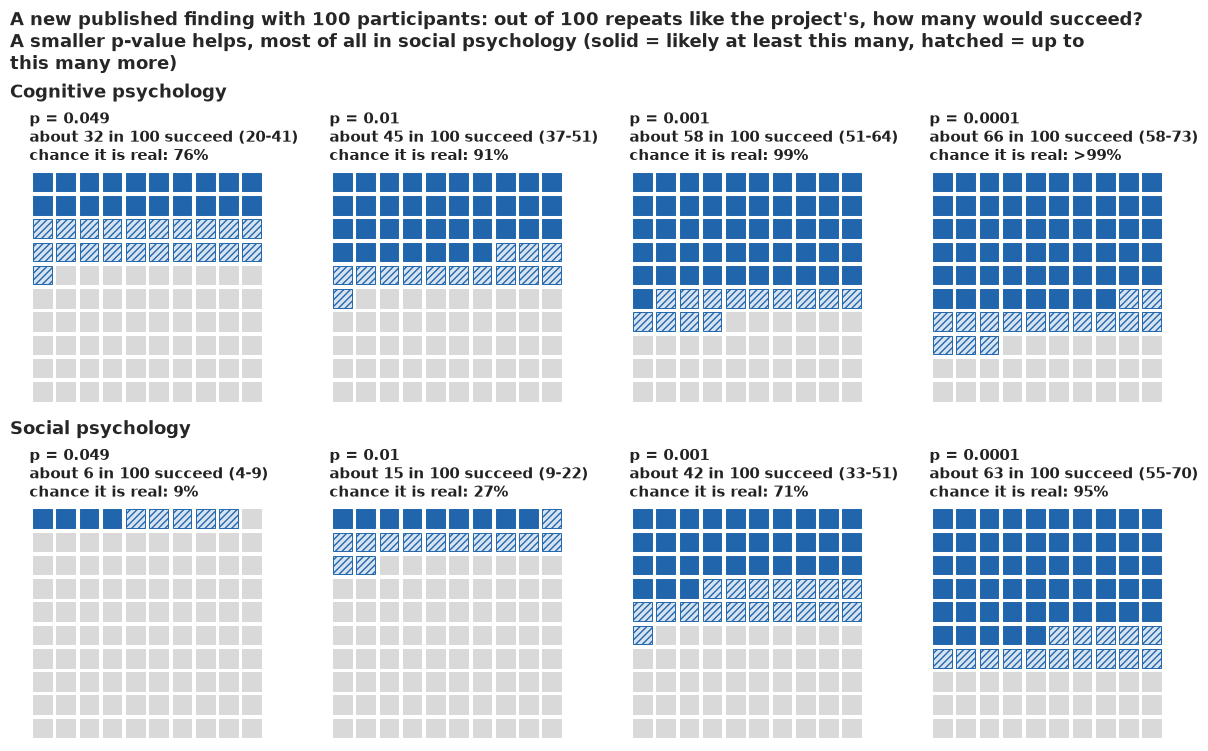

In [23]:
LADDER_P = (0.049, 0.01, 0.001, 0.0001)
fig = plt.figure(figsize=(12, 7.4))
subs = fig.subfigures(2, 1)
for j, (f, sf) in enumerate(zip(FIELDS, subs)):
    axs = sf.subplots(1, 4)
    for ax, p in zip(axs, LADDER_P):
        s_ = 1 / np.sqrt(97)
        pr = predict(P_FULL, np.array([j]), np.array([stats.norm.isf(p / 2) * s_]),
                     np.array([s_]), np.array([s_]))
        lo_, _, hi_ = pub.freq_range(pr["p_succ"], 100)
        mid_ = int(np.clip(round(100 * pr["p_succ"].mean()), lo_, hi_))  # the table's mean
        pub.icon_array(ax, lo_, mid_, hi_, n=100, shape="square", key=False, title=False)
        ax.set_title(f"p = {p:g}\nabout {mid_} in 100 succeed ({lo_}-{hi_})\n"
                     f"chance it is real: {pub.fmt_pct(pr['p_real'].mean())}", fontsize=11,
                     loc="left", color=INK)
    sf.suptitle(f"{f} psychology", x=0.01, ha="left", fontsize=13, weight="bold")
fig.suptitle(wrap("A new published finding with 100 participants: out of 100 repeats like the "
                  "project's, how many would succeed? A smaller p-value helps, most of all in "
                  "social psychology (solid = likely at least this many, hatched = up to this "
                  "many more)", 110),
             x=0.01, ha="left", fontsize=13);

Each row climbs as the p-value shrinks. The rows start far apart (about 32 against 6 repeats in
100 at p = .049) and nearly meet at p = .0001 (about 66 against 63). In every panel fewer repeats
succeed than the chance that the finding is real. The panel to remember is the bottom-left one:
a just-significant social-psychology finding rarely shows up again.

## G · Explaining it to everyone

### The statistician's plot

A forecaster's standard check is the **reliability diagram**: the held-out forecasts cut into
ten equal bins, the observed frequency of success in each bin with a binomial interval, the
diagonal for perfect calibration, a histogram of the forecasts below, and the Brier and log
scores and the AUC in the title.

     bin  n  k
  0%-10% 10  3
 10%-20% 16  2
 20%-30% 10  2
 30%-40%  6  2
 40%-50% 11  4
 50%-60% 11  6
 60%-70%  7  3
 70%-80%  2  2
90%-100%  3  2


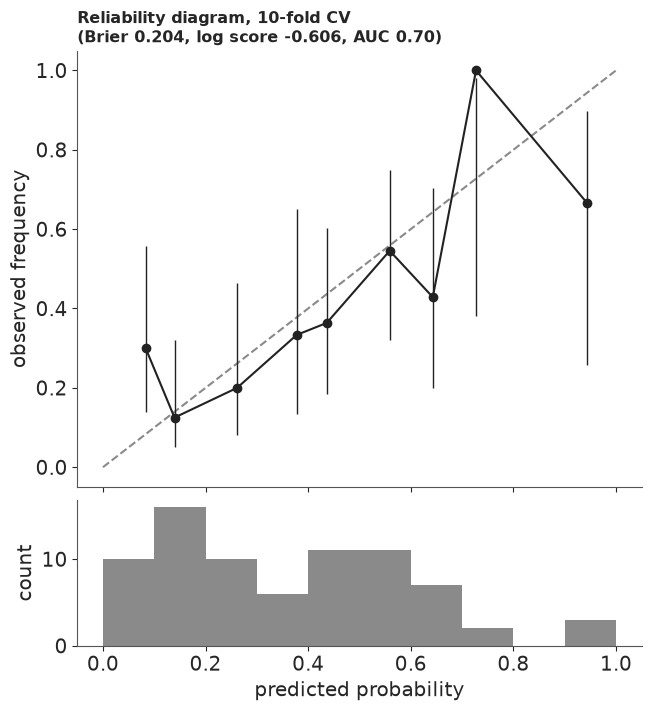

In [24]:
def binned(p, edges, y=Y):
    b = np.clip(np.digitize(p, edges) - 1, 0, len(edges) - 2)
    out = []
    for j in range(len(edges) - 1):
        m_ = b == j
        if m_.sum():
            k, nn = int(y[m_].sum()), int(m_.sum())
            lo_, hi_ = stats.beta.ppf([0.055, 0.945], 1 + k, 1 + nn - k)
            out.append(dict(bin=f"{edges[j]:.0%}-{edges[j + 1]:.0%}", n=nn, k=k, x=p[m_].mean(),
                            obs=k / nn, lo=lo_, hi=hi_))
    return pd.DataFrame(out)


P_CV = CV["filter + field + imperfect repeat"]
SC = scores(P_CV)
E10 = np.linspace(0, 1, 11)
B10 = binned(P_CV, E10)
fig, (a1, a2) = plt.subplots(2, 1, figsize=(6.4, 7), height_ratios=[3, 1], sharex=True)
a1.plot([0, 1], [0, 1], color=MUTED, ls="--")
a1.vlines(B10.x, B10.lo, B10.hi, color=INK, lw=1)  # a Beta interval need not contain 0 of n
a1.plot(B10.x, B10.obs, "o-", color=INK)
a1.set_ylabel("observed frequency")
a1.set_title(f"Reliability diagram, 10-fold CV\n(Brier {SC['brier']:.3f}, log score "
             f"{SC['log_score']:.3f}, AUC {SC['auc']:.2f})", fontsize=11.5, loc="left")
a2.hist(P_CV, bins=E10, color=MUTED)
a2.set_xlabel("predicted probability")
a2.set_ylabel("count")
print(B10[["bin", "n", "k"]].to_string(index=False))

For a statistician this says what is needed: the points scatter around the diagonal, mostly
below it above 30%. For anyone else it fails. Two bins hold two or three studies, so their
points jump about; "observed frequency" and "predicted probability" are words for the trained;
and the scores mean nothing without a comparison.

### The track-record plot

The public version asks a question anyone can check: **when the model said about 30%, did it
happen about 30% of the time?** It uses five bins, labels each dot with its count ("4 of 16"),
sizes it by the number of studies, and gives each bin a grey bar for where the true share
plausibly lies (the 89% range of a Beta(1 + k, 1 + n - k) posterior). In vermilion are two ghosts
of overconfidence, the naive mixture and the rule "p < .05 means it will replicate"; in green,
the simple rule to beat. The title states the verdict in counts by a rule fixed in the code
("about right" within one standard deviation of the count, 3.7 here); the subtitle carries the
comparison with the simple rule and, when clearly below 1, the calibration slope, from a logistic
regression of the outcome on the forecast's log-odds. Track records are how weather forecasters
earn trust: probabilistic forecasts improve decisions and soften the loss of trust after a miss
(Joslyn & LeClerc 2012, *J. Experimental Psychology: Applied*), and honest uncertainty costs
little trust (van der Bles et al. 2020, *PNAS*).

     bin  n  k    x  obs   lo   hi
  0%-20% 26  5 0.12 0.19 0.10 0.35
 20%-40% 16  4 0.31 0.25 0.13 0.45
 40%-60% 22 10 0.50 0.45 0.30 0.62
 60%-80%  9  5 0.66 0.56 0.31 0.77
80%-100%  3  2 0.94 0.67 0.26 0.90
     bin  n  k    x  obs
 20%-40%  5  1 0.33 0.20
 40%-60%  7  2 0.52 0.29
 60%-80% 33  9 0.72 0.27
80%-100% 31 14 0.88 0.45
expected 27.7, observed 26, sd of the count 3.7: gap 0.5 sd
calibration slope 0.60 (89% 0.24-0.95), intercept -0.31 (se 0.28)


The model's odds were about right: it expected 28 of the 76 repeats to succeed, and 26 did
Of published findings like these, it is *virtually certain* (99.3%) that most are real effects: *virtually certain* (>99.9%) for cognitive psychology, but *unlikely* (16%) for social psychology. We have *medium confidence*: the figures rest on 76 pairs and on model changes made after a first look at the forecasts.


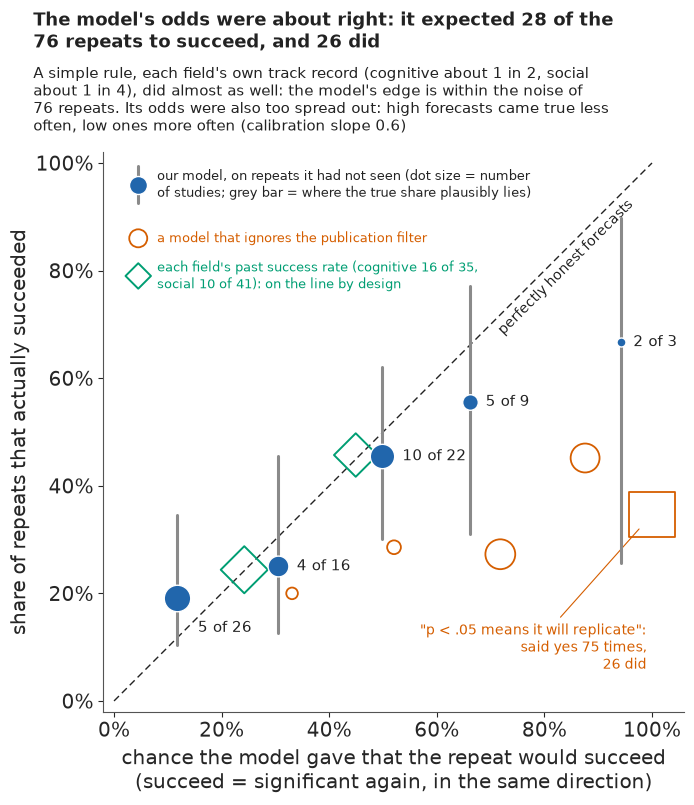

In [25]:
E5 = np.linspace(0, 1, 6)
B5, B5_NAIVE = binned(P_CV, E5), binned(CV["naive mixture"], E5)
print(B5.round(2).to_string(index=False))
print(B5_NAIVE[["bin", "n", "k", "x", "obs"]].round(2).to_string(index=False))
EXP, OBS = P_CV.sum(), int(Y.sum())
SD_PB = np.sqrt(np.sum(P_CV * (1 - P_CV)))  # sd of the success count if the forecasts were right
GAP = (EXP - OBS) / SD_PB
VERDICT = ("about right" if abs(GAP) <= 1 else "a little too hopeful" if 1 < GAP <= 2 else
           "too hopeful" if GAP > 2 else "a little too cautious" if GAP >= -2 else "too cautious")
print(f"expected {EXP:.1f}, observed {OBS}, sd of the count {SD_PB:.1f}: gap {GAP:.1f} sd")
# calibration slope: a logistic regression of the outcome on the forecast's log-odds (1 if the
# forecasts are spread just right, below 1 if they are too spread out), by Newton's method
X_CAL = np.column_stack([np.ones(n), special.logit(np.clip(P_CV, 1e-6, 1 - 1e-6))])
b_cal = np.zeros(2)
for _ in range(30):
    pr_ = special.expit(X_CAL @ b_cal)
    H_cal = X_CAL.T @ (X_CAL * (pr_ * (1 - pr_))[:, None])
    b_cal = b_cal + np.linalg.solve(H_cal, X_CAL.T @ (Y - pr_))
pr_ = special.expit(X_CAL @ b_cal)
se_cal = np.sqrt(np.diag(np.linalg.inv(X_CAL.T @ (X_CAL * (pr_ * (1 - pr_))[:, None]))))
SLOPE, SLOPE_LO, SLOPE_HI = b_cal[1], b_cal[1] - 1.598 * se_cal[1], b_cal[1] + 1.598 * se_cal[1]
print(f"calibration slope {SLOPE:.2f} (89% {SLOPE_LO:.2f}-{SLOPE_HI:.2f}), intercept "
      f"{b_cal[0]:.2f} (se {se_cal[0]:.2f})")
HEAD_TITLE = (f"The model's odds were {VERDICT}: it expected {EXP:.0f} of the {n} repeats to "
              f"succeed, and {OBS} did")
LS_D, LS_SE = paired("filter + field + imperfect repeat", "field base rate (training folds)")[
    "log score"]
HEAD_SUB = ("It beat a simple rule, each field's own track record (cognitive about 1 in 2, social "
            "about 1 in 4)" if LS_D > 2 * LS_SE else
            "A simple rule, each field's own track record (cognitive about 1 in 2, social about "
            "1 in 4), did almost as well: the model's edge is within the noise of 76 repeats")
if SLOPE_HI < 1:
    HEAD_SUB += (f". Its odds were also too spread out: high forecasts came true less often, "
                 f"low ones more often (calibration slope {SLOPE:.1f})")
PSIG = ~MARG  # presented to the journal as p < .05
FIELD_PTS = [(CV["field base rate (training folds)"][G == j].mean(), Y[G == j].mean(),
              (G == j).sum(), f.lower()) for j, f in enumerate(FIELDS)]
FIELD_C = "#009e73"  # Okabe-Ito bluish green: the simple rule, apart from the grey ranges


def track_record_figure(title=HEAD_TITLE, sub=HEAD_SUB):
    fig, ax = plt.subplots(figsize=(7.0, 8.2), layout="none")
    fig.subplots_adjust(left=0.13, right=0.96, top=0.83, bottom=0.11)
    ax.plot([0, 1], [0, 1], color=INK, lw=1, ls=(0, (5, 3)), zorder=1)
    ax.text(0.83, 0.815, "perfectly honest forecasts", rotation=45, rotation_mode="anchor",
            ha="center", va="top", fontsize=10, color=INK)
    for r in B5_NAIVE.itertuples():
        ax.scatter(r.x, r.obs, s=14 * r.n, facecolor="none", edgecolor=LO, lw=1.3, zorder=2)
    ax.scatter([1.0], [Y[PSIG].mean()], s=14 * PSIG.sum(), marker="s", facecolor="none",
               edgecolor=LO, lw=1.3, zorder=2, clip_on=False)
    ax.annotate(f'"p < .05 means it will replicate":\nsaid yes {PSIG.sum()} times,\n'
                f'{Y[PSIG].sum()} did', (1.0, Y[PSIG].mean()), xytext=(0.99, 0.06),
                ha="right", fontsize=10, color=LO,
                arrowprops=dict(arrowstyle="-", color=LO, lw=0.8, shrinkB=14))
    for fx, fy, fn, fl in FIELD_PTS:
        ax.scatter(fx, fy, s=14 * fn, marker="D", facecolor="none", edgecolor=FIELD_C, lw=1.4,
                   zorder=2)
    for r in B5.itertuples():
        ax.plot([r.x, r.x], [r.lo, r.hi], color=MUTED, lw=2.2, zorder=3, solid_capstyle="round")
        ax.scatter(r.x, r.obs, s=14 * r.n, color=HI, zorder=4, edgecolor="white", lw=1)
        rad = np.sqrt(14 * r.n / np.pi)
        low = r.x < 0.2  # the first bin: below and right, clear of the diagonal and a diamond
        ax.annotate(f"{r.k} of {r.n}", (r.x, r.obs),
                    xytext=(rad + 4, -rad - 6) if low else (rad + 5, 0),
                    textcoords="offset points", ha="left", va="top" if low else "center",
                    fontsize=10.5, color=INK, zorder=5)
    # a key in the empty top-left corner
    kx, ky = 0.03, 0.96
    ax.scatter([kx + 0.015], [ky], s=14 * 12, color=HI, edgecolor="white")
    ax.plot([kx + 0.015] * 2, [ky - 0.035, ky + 0.035], color=MUTED, lw=2.2, zorder=0)
    ax.text(kx + 0.05, ky, "our model, on repeats it had not seen (dot size = number\nof "
            "studies; grey bar = where the true share plausibly lies)", va="center",
            fontsize=9.5, color=INK)
    ax.scatter([kx + 0.015], [ky - 0.1], s=14 * 12, facecolor="none", edgecolor=LO, lw=1.3)
    ax.text(kx + 0.05, ky - 0.1, "a model that ignores the publication filter", va="center",
            fontsize=9.5, color=LO)
    ax.scatter([kx + 0.015], [ky - 0.17], s=14 * 12, marker="D", facecolor="none",
               edgecolor=FIELD_C, lw=1.4)
    ax.text(kx + 0.05, ky - 0.17, "each field's past success rate (cognitive "
            f"{Y[G == 0].sum()} of {(G == 0).sum()},\nsocial {Y[G == 1].sum()} of "
            f"{(G == 1).sum()}): on the line by design", va="center", fontsize=9.5,
            color=FIELD_C)
    ax.set_xlim(-0.02, 1.06)
    ax.set_ylim(-0.02, 1.02)
    ax.set_aspect("equal")
    ticks = np.linspace(0, 1, 6)
    ax.set_xticks(ticks, [f"{t:.0%}" for t in ticks])
    ax.set_yticks(ticks, [f"{t:.0%}" for t in ticks])
    ax.set_xlabel("chance the model gave that the repeat would succeed\n"
                  "(succeed = significant again, in the same direction)")
    ax.set_ylabel("share of repeats that actually succeeded")
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    t_ = wrap(title, 58)
    fig.text(0.03, 0.985, t_, fontsize=13, weight="bold", color=INK, va="top")
    fig.text(0.03, 0.985 - 0.03 * (t_.count("\n") + 1) - 0.008, wrap(sub, 76), fontsize=10.5,
             color=INK, va="top")
    return fig


fig_top = track_record_figure()
HEADLINE.update(fig_top)  # the copy at the top of the notebook
plt.close(fig_top)
track_record_figure()
print(HEAD_TITLE)
P_MOST = {k: float(np.mean(v > 0.5)) for k, v in SH.items()}


def pct_num(p):
    """A probability to one decimal near the ends, so that it agrees with its calibrated word."""
    return (">99.9%" if p >= 0.9995 else "<0.1%" if p < 0.0005 else
            f"{p:.1%}" if (p > 0.95 or p < 0.05) else f"{p:.0%}")


def word_pct(p):
    return f"*{pub.calibrated_word(p)}* ({pct_num(p)})"


SURE = (f"Of published findings like these, it is {word_pct(P_MOST['all'])} that most are real "
        f"effects: {word_pct(P_MOST['Cognitive'])} for cognitive psychology, but "
        f"{word_pct(P_MOST['Social'])} for social psychology. We have *medium confidence*: the "
        f"figures rest on 76 pairs and on model changes made after a first look at the forecasts.")
print(SURE)
HOW_SURE.update(Markdown("**How sure are we.** " + SURE))

The blue dots climb with the forecasts: where the model said about 12%, 5 of the largest bin of
26 succeeded; about 30%, 4 of 16; about half, 10 of 22; about two thirds, 5 of 9; about 94%, 2
of 3. Four of the five grey ranges cross the diagonal and the top one ends just
short of it. But the lowest dot sits above the line and every dot above 20% below it, the
signature of forecasts too spread out: the calibration slope is 0.6 (89% interval 0.24-0.95), so
the total is about right while the model is too sure in both directions, as the subtitle says.
The green diamonds of the field rule sit on the diagonal by construction: any base rate matches
its own field's average, so they show nothing about skill, and the subtitle's score comparison is
the real test. The vermilion ghosts show overconfidence on the same axes: the naive mixture said
72% where 9 of 33 succeeded, and "p < .05 means it will replicate" said yes 75 times for 26
successes. One pitfall remains: a reader may take the diagonal for "the truth" rather than a
standard to meet, which its label tries to prevent.

### Icon shelves: which findings were real?

The second display moves to the studies themselves. Each person-shaped icon is one of the 76
studies, filled from the bottom up to its chance of being real once its repeat is seen, and
placed on one of three shelves: a natural-frequency display of 76 separate probabilities (Galesic
et al. 2009). The shared `pub.icon_array` fills whole icons only, so the partial fill is a local
helper, a rectangle clipped to each icon.

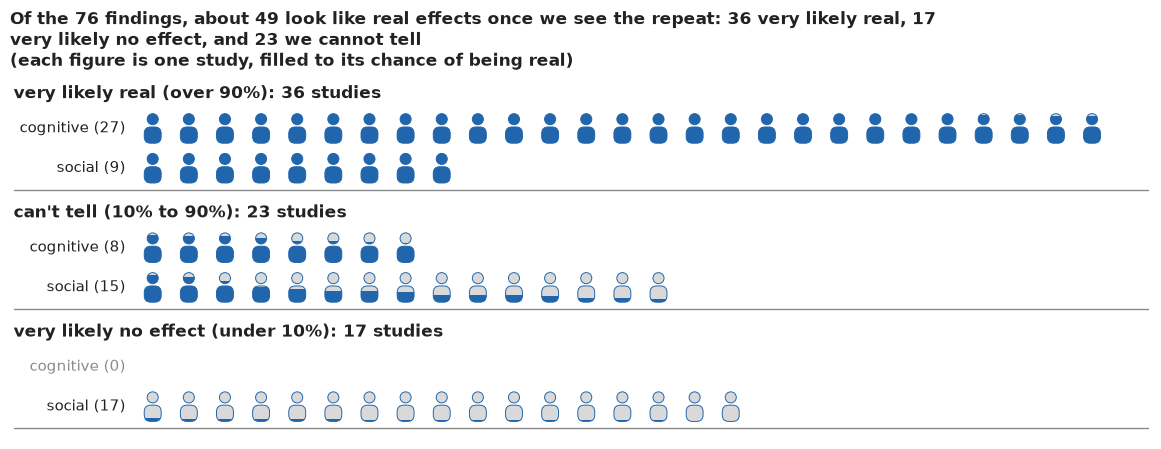

In [26]:
def person_fill(ax, x, y0, s, frac, fc=HI, base=LIGHT):
    """A person icon at (x, y0), size s, filled from the bottom to `frac` of its height."""
    def shapes():
        return (Circle((x + 0.5 * s, y0 + 0.78 * s), 0.17 * s),
                FancyBboxPatch((x + 0.24 * s, y0 + 0.04 * s), 0.52 * s, 0.5 * s,
                               boxstyle=f"round,pad=0,rounding_size={0.2 * s}"))
    for shp, outline in zip(shapes(), shapes()):
        shp.set(fc=base, ec="none")
        ax.add_patch(shp)
        fill = Rectangle((x, y0 + 0.04 * s), s, frac * 0.93 * s, fc=fc, ec="none")
        ax.add_patch(fill)
        fill.set_clip_path(shp)
        outline.set(fc="none", ec=fc, lw=0.7)
        ax.add_patch(outline)


SHELF_LAB = ["very likely real (over 90%)", "can't tell (10% to 90%)",
             "very likely no effect (under 10%)"]
NCOL, X0 = 28, 3.4
fig, ax = plt.subplots(figsize=(11.5, 7.4))
ytop = 0.0
for sh in range(3):
    ax.text(0, ytop - 0.1, f"{SHELF_LAB[sh]}: {(SHELF == sh).sum()} studies", fontsize=12.5,
            weight="bold", color=INK, va="top")
    ytop -= 0.75
    for j, f in enumerate(FIELDS):
        idx = np.where((SHELF == sh) & (G == j))[0]
        idx = idx[np.argsort(-PB[idx])]
        nrow = max(1, int(np.ceil(len(idx) / NCOL)))
        ax.text(X0 - 0.3, ytop - 0.55, f"{f.lower()} ({len(idx)})", ha="right", va="center",
                fontsize=11, color=INK if len(idx) else MUTED)
        for i, k in enumerate(idx):
            r, c = divmod(i, NCOL)
            person_fill(ax, X0 + c, ytop - 1.0 - r, 0.9, PB[k])
        ytop -= nrow + 0.1
    ax.plot([0, X0 + NCOL], [ytop - 0.05] * 2, color=MUTED, lw=1)
    ytop -= 0.35
ax.set_xlim(-0.1, X0 + NCOL + 0.1)
ax.set_ylim(ytop, 0.2)
ax.set_aspect("equal")
ax.axis("off")
ax.set_title(wrap(f"Of the {n} findings, about {PB.sum():.0f} look like real effects once we see "
                  f"the repeat: {(SHELF == 0).sum()} very likely real, {(SHELF == 2).sum()} very "
                  f"likely no effect, and {(SHELF == 1).sum()} we cannot tell", 100)
             + "\n(each figure is one study, filled to its chance of being real)", loc="left",
             fontsize=12.5, color=INK);

The shelves make the field difference concrete without a percentage: the top shelf is mostly
cognitive, the bottom shelf entirely social, and the middle shelf, mostly social, is where the
honest answer is "we can't tell". The shelf a study lands on moved by a few studies in part
E, which is why the figure shows no study names. And the shelves are about whether an effect is
real, not whether it will repeat, a difference the ladder of part F carries.

### Words with numbers

The field-level claim, "most published findings are real", is a probability, so it gets the
calibrated-language strip used throughout this set: the IPCC's likelihood words (Mastrandrea et
al. 2010) placed on a 0-100% scale, with the number beside the word, since readers interpret the
words alone very differently (Budescu, Broomell & Por 2009, *Psychological Science*).

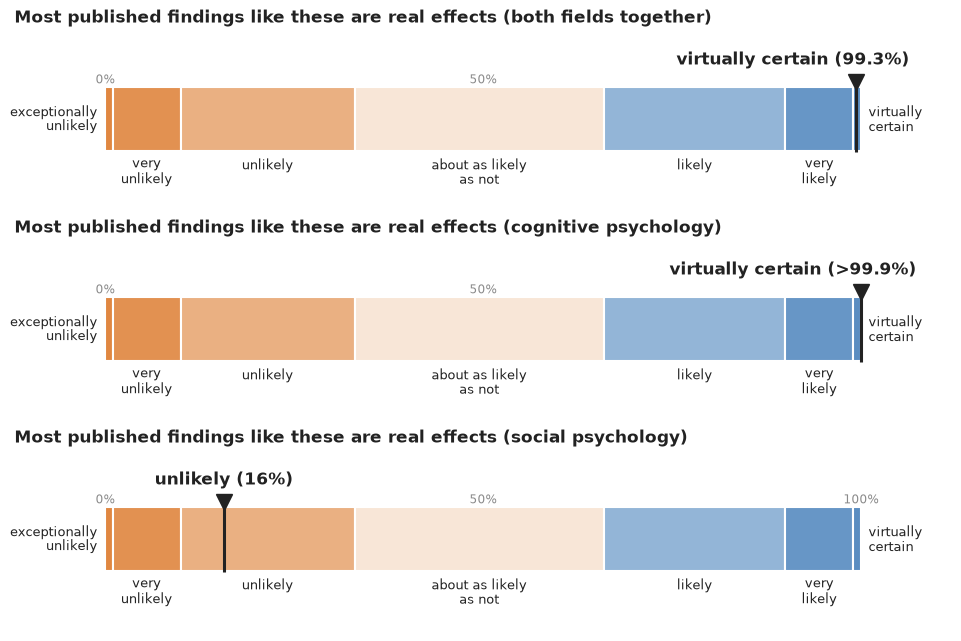

In [27]:
fig, axs = plt.subplots(3, 1, figsize=(9.5, 6.3))
for ax, key, lab in zip(axs, ("all", "Cognitive", "Social"),
                        ("both fields together", "cognitive psychology", "social psychology")):
    p_ = float(np.mean(SH[key] > 0.5))
    pub.word_strip(ax, p_, f"Most published findings like these are real effects ({lab})")
    for t_ in ax.texts:  # the strip's own label rounds to whole percents: use the text's number
        if t_.get_text() == f"{pub.calibrated_word(p_)} ({pub.fmt_pct(p_)})":
            t_.set_text(f"{pub.calibrated_word(p_)} ({pct_num(p_)})")

For the two fields together and for cognitive psychology "most are real" is virtually certain;
for social psychology it is unlikely. The top strip averages over two fields that differ. The
strips say how sure the *model* is; how much to trust the model is the "medium confidence" of
the summary at the top, with its reason.

### The publication filter, animated

The idea of a filter is easier to see than to read. The animation runs 1,000 studies from the
fitted model, 25 per frame, slot by slot as in the prior predictive check, so that the published
pile has the make-up of the 76 originals. The top panel stacks every study as it is run; the
bottom panel keeps only those that pass the filter, with the average effect they found and their
true average. Watching the frames fill in is a **hypothetical outcome plot** (Hullman, Resnick &
Adar 2015, *PLOS ONE*), at 0.5 s a frame, below the three flashes a second that accessibility
guidance forbids.

wrote E117_would_it_replicate_filter.gif: 40 frames, 640x512 px, 0.4 MB
1000 simulated studies: 23% real; published 67 (7%), of which 72% real; average r found 0.45 against true 0.34


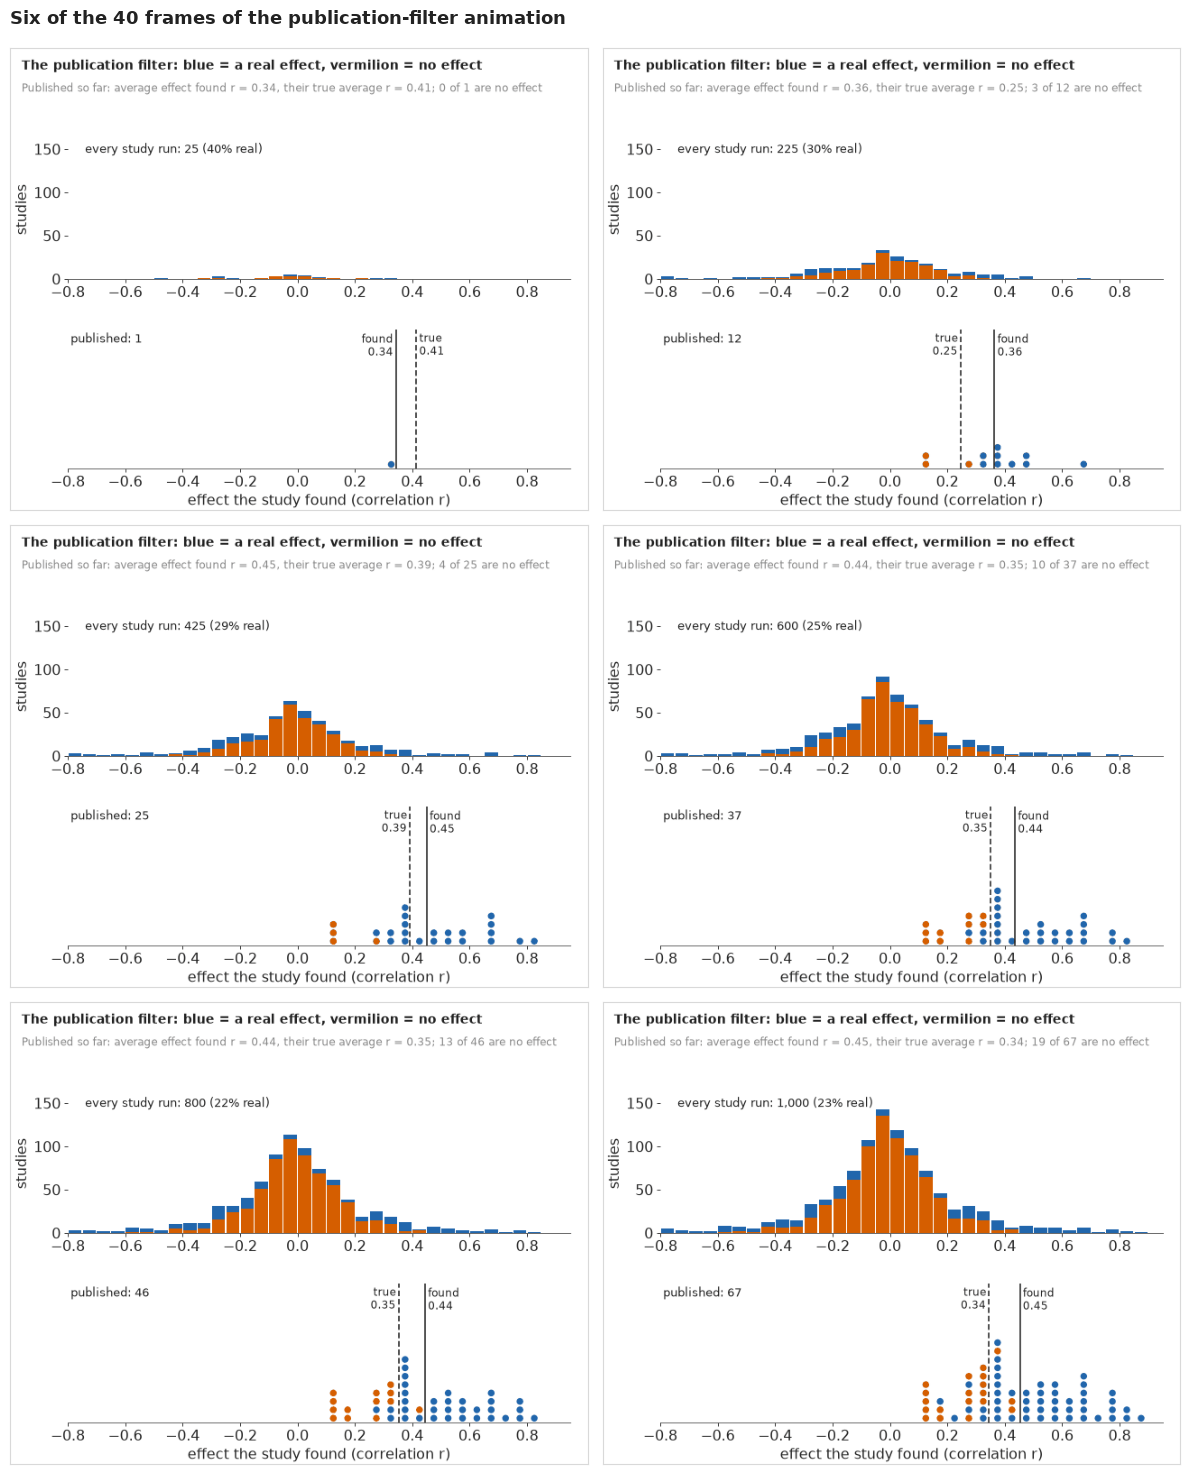

In [28]:
NB_STEM = "E117_would_it_replicate"
GIF = f"{NB_STEM}_filter.gif"  # written next to the notebook: the site copies every {stem}*.gif
NF, PER = 40, 25
M_G = NF * PER
gr = np.random.default_rng(7)
# As in the prior predictive check: pick one of the 76 slots (its field and precision) and one
# posterior draw, run studies until one passes the filter, then move on to another slot. Every
# published study then stands for one slot, as the 76 do, and the runs are all the attempts.
real_g, yo_g, th_g, pub_g = [], [], [], []
while len(yo_g) < M_G:
    k, i = gr.integers(n), gr.integers(len(P_FULL["mu"]))
    while len(yo_g) < M_G:
        c = gr.random() < P_FULL["pi"][i, G[k]]
        th = gr.normal(P_FULL["mu"][i], P_FULL["tau"][i]) if c else 0.0
        y_ = gr.normal(th, sO[k])
        z_ = y_ / sO[k]
        ok = gr.random() < (1.0 if z_ >= Z196 else P_FULL["w_marg"][i] if z_ >= Z1645 else 0.0)
        real_g.append(c), yo_g.append(y_), th_g.append(th), pub_g.append(ok)
        if ok:
            break
real_g, yo_g, th_g, pub_g = (np.array(a) for a in (real_g, yo_g, th_g, pub_g))
r_g, rt_g = np.tanh(yo_g), np.tanh(th_g)
EDG = np.arange(-0.8, 0.951, 0.05)
CEN = 0.5 * (EDG[1:] + EDG[:-1])
col_g = np.clip(np.digitize(r_g, EDG) - 1, 0, len(CEN) - 1)
RUN_MAX = np.bincount(col_g, minlength=len(CEN)).max()
PUB_MAX = np.bincount(col_g[pub_g], minlength=len(CEN)).max()
PUB_TOP = PUB_MAX * 1.35 + 3  # head room for the labels above the stacked dots
fig_g = plt.figure(figsize=(8, 6.4), dpi=80, layout="none")
a_run = fig_g.add_axes([0.10, 0.50, 0.87, 0.30])
a_pub = fig_g.add_axes([0.10, 0.09, 0.87, 0.30])
DOT = min(0.8 * 0.30 * 6.4 * 72 / PUB_TOP, 11.0)


def filter_frame(f):
    m = (f + 1) * PER
    for ax in (a_run, a_pub):
        ax.clear()
        for s in ("left", "right", "top"):
            ax.spines[s].set_visible(False)
        ax.set_xlim(-0.8, 0.95)
    hr = np.bincount(col_g[:m][real_g[:m]], minlength=len(CEN))
    hn = np.bincount(col_g[:m][~real_g[:m]], minlength=len(CEN))
    a_run.bar(CEN, hn, width=0.046, color=LO, lw=0)
    a_run.bar(CEN, hr, bottom=hn, width=0.046, color=HI, lw=0)
    a_run.set_ylim(0, RUN_MAX * 1.12)
    a_run.set_ylabel("studies")
    a_run.text(-0.74, RUN_MAX * 1.1, f"every study run: {m:,} ({real_g[:m].mean():.0%} real)",
               fontsize=12, va="top", color=INK)
    pj = np.where(pub_g[:m])[0]
    height, xs, ys, cs = {}, [], [], []
    for j in pj:
        h_ = height.get(col_g[j], 0)
        xs.append(CEN[col_g[j]])
        ys.append(h_ + 0.5)
        cs.append(HI if real_g[j] else LO)
        height[col_g[j]] = h_ + 1
    a_pub.scatter(xs, ys, s=DOT**2, c=cs, lw=0)
    a_pub.set_ylim(0, PUB_TOP)
    a_pub.set_yticks([])
    a_pub.set_xlabel("effect the study found (correlation r)")
    a_pub.text(-0.79, PUB_TOP * 0.98, f"published: {len(pj)}", fontsize=12, va="top", color=INK)
    if len(pj):
        fa, ta = r_g[pj].mean(), rt_g[pj].mean()
        a_pub.axvline(fa, color=INK, lw=1.4)
        a_pub.axvline(ta, color=INK, lw=1.4, ls=(0, (4, 2)))
        for v_, lab_, right_ in ((fa, "found", fa >= ta), (ta, "true", ta > fa)):
            a_pub.text(v_ + (0.01 if right_ else -0.01), PUB_TOP * 0.98, f"{lab_}\n{v_:.2f}",
                       fontsize=10.5, va="top", ha="left" if right_ else "right")
    fig_g.texts.clear()
    fig_g.text(0.02, 0.975, "The publication filter: blue = a real effect, vermilion = no effect",
               fontsize=13, weight="bold", va="top", color=INK)
    if len(pj):
        fig_g.text(0.02, 0.925, f"Published so far: average effect found r = {fa:.2f}, their "
                   f"true average r = {ta:.2f}; {int((~real_g[pj]).sum())} of {len(pj)} are no "
                   "effect", fontsize=11, va="top", color=MUTED)


t0 = time.time()
frames = pub.save_gif(fig_g, filter_frame, NF, GIF, ms=500)
plt.close(fig_g)
TIMES["GIF"] = time.time() - t0
print(f"{M_G} simulated studies: {real_g.mean():.0%} real; published {pub_g.sum()} "
      f"({pub_g.mean():.0%}), of which {real_g[pub_g].mean():.0%} real; average r found "
      f"{r_g[pub_g].mean():.2f} against true {rt_g[pub_g].mean():.2f}")
pub.gif_contact_sheet(frames, title=f"Six of the {NF} frames of the publication-filter animation");

The animation is saved as
[E117_would_it_replicate_filter.gif](E117_would_it_replicate_filter.gif), small enough for a
message or a slide; the six frames above are its static companion, with the alt text below for
screen readers.

![Animated publication filter: in the top panel, simulated psychology studies pile up as they
are run, most of them no-effect studies centred on zero; in the bottom panel only the published
ones appear, about 1 in 15, all to the right of zero, with an average effect found well above
their true average](E117_would_it_replicate_filter.gif)

This is the model's own world: most hypotheses tested are null, the published pile is a thin
slice of the right tail, and its average effect is well above the truth behind it. The pile ends
72% real, against the 65% the model gives for the 76 originals, a gap within the noise of 67
published studies. The price of the GIF is a simulated world that readers may take for data.

### What the public version gives up

Next to the reliability diagram, the track-record plot drops the proper scores, and with them
the finding a specialist cares most about: the model's edge over a field base rate is within the
noise. A track record that looks "about right" can still be no better than a simple rule, which
is why the subtitle is part of the figure.

In [29]:
TIMES["total"] = time.time() - T_START
print({k: round(v, 1) for k, v in TIMES.items()})

{'compile naive': 5.8, 'naive mixture': 0.1, 'compile filter': 4.2, 'filter, one shared share': 0.3, '10-fold naive mixture': 1.0, '10-fold filter, one shared share': 2.7, 'compile full': 4.6, 'filter + field shares + imperfect repeat': 0.3, '10-fold full model': 3.3, 'recovery fit': 0.3, '19 more recovery fits': 6.9, '10 worlds with a published share of 0.45': 3.8, 'compile extra step at p = .01': 5.4, 'extra step at p = .01': 0.4, '10-fold extra step at p = .01': 4.0, 'compile slab leans positive': 4.6, 'slab leans positive': 0.3, '10-fold slab leans positive': 3.0, 'compile wide repeat priors': 4.9, 'wide repeat priors': 0.3, '10-fold wide repeat priors': 3.3, 'compile flat prior on w_marg': 4.6, 'flat prior on w_marg': 0.3, '10-fold flat prior on w_marg': 3.3, 'compile four near .05 marginal': 4.6, 'four near .05 marginal': 0.3, '10-fold four near .05 marginal': 3.3, 'GIF': 6.2, 'total': 92.4}


## Summary

- **Effective sample size is a data problem before it is a model problem.** With the head count,
  the z-statistics of $t$ and $F$ tests disagreed with their p-values in a tail (5-95% of the
  ratio 0.93-1.29); the test's degrees of freedom plus two brought it to 1.00-1.05. Of 97 pairs,
  76 one-df tests of claimed effects can be modelled; 26 of their repeats succeeded.
- **A filter makes real findings look bigger and repeats look like failures.** In a toy world
  with half the hypotheses real, the published record was 93% real yet reported effects 1.6 times
  the truth, and only about 37% of exact repeats would succeed.
- **Ignoring the filter fails badly.** A mixture fitted to published originals at face value
  expected 56 successful repeats out of sample where 26 happened (log score -1.2).
- **The selection likelihood is closed form**, checked against quadrature on three pairs, with
  the weight and the probability of publication read from the same z-statistic. The weight for
  marginal results rests on one to four originals (0.06-0.19 across codings and priors), while
  the shares and the track record barely move.
- **The filter alone lost to "about 1 in 3"** (log score -0.80 against -0.66). A share per field
  and an imperfect repeat ($\lambda$ about 0.78, a between-site spread of about 0.19), both added
  after seeing that, gave forecasts about right in total (28 expected, 26 observed) and better
  than both base rates on Brier and log score, but within one standard error of the field base
  rate, and too spread out (calibration slope 0.6).
- **About 65% of published findings like these are real effects** (55-74%; "most are real"
  virtually certain), pooling about 93% in cognitive and 41% in social psychology, where "most
  are real" is unlikely. Simulation recovered the share without bias at the fitted truth; where
  the truth was 0.45 the model overestimated it (mean 0.54) but never called "most are real"
  virtually certain. Once the repeats are seen, 36 of 76 studies are very likely real, 17 very
  likely null and 23 undecided, give or take a few.
- **Real is not replicates.** For a new finding with 100 people, a repeat like the project's
  succeeds about 32 times in 100 at p = .049 in cognitive psychology and 6 in social; at
  p = .0001, about 66 and 63, although such findings are almost surely real. In large repeats
  the between-site spread, not the sample size, sets the odds.
- **The public track-record plot says the verdict in counts** (28 expected, 26 happened) and
  shows the field rule beside it; it gives up the proper scores, so its subtitle must say that
  the simple rule did almost as well. Shelves, a risk ladder, word strips and a GIF carry the
  rest.

## Try it yourself

1. **A different outcome.** Replace "significant in the same direction" by the project's own
   yes/no coding (`osc_replicate`), or by "the repeat's effect lies inside the original's 95%
   interval", and redo the track record. Which outcome does the model forecast best, and does
   the field base rate still match it?
2. **Heavier tails for real effects.** Replace the normal slab by a Student-t or a two-component
   normal mixture (written in the same closed form, component by component). Do the icon shelves
   settle down, and does the log score finally beat the field base rate?
3. **A new test set.** The Social Sciences Replication Project (Camerer et al. 2018, *Nature
   Human Behaviour*) repeated 21 experiments from *Nature* and *Science*. Code its pairs the way
   `tools/build_e117_rpp.py` does, forecast them with the model fitted here, and draw a second
   track record: an honest test, since nothing in this notebook was chosen after seeing it.